# TrendWeave - AI Fashion Product Strategy Agent

> SPA 기업의 다음 시즌 상품기획을 지원하는 AI 리서치 및 의사결정 Agent

**목차**

1. 주제 선정
2. 요구사항 분석
3. 아키텍처 설계
4. Tool 설계
5. 프로토타입 구현

## 1. 주제 선정

### 1.1 기획 배경

본 프로젝트는 SPA 브랜드의 상품기획자와 MD가 다음 시즌 트렌드를 조사하고, 자사 브랜드에 적용할 상품 방향을 정하는 과정을 지원하는 AI 리서치 및 의사결정 보조 시스템을 만드는 것을 목표로 한다.

SPA 기업의 상품기획자는 실제 판매 시점보다 앞서 다음 시즌 상품을 준비해야 하므로, 패션위크와 주요 브랜드 컬렉션에서 나타나는 트렌드를 빠르게 파악해야 한다. 동시에 현재 소비자들이 어떤 스타일에 반응하고 있는지, 시장에서는 어떤 상품과 키워드가 주목받고 있는지, 자사 및 경쟁 브랜드는 어떤 상품을 전개하고 있는지도 함께 고려해야 한다.

문제는 이러한 정보가 패션 기사, 컬렉션 리뷰, 시장 동향 자료, 브랜드 공식 홈페이지 등 여러 출처에 흩어져 있다는 점이다. 담당자는 많은 자료를 직접 검색하고 읽은 뒤, 서로 다른 정보를 연결하여 "이 트렌드를 우리 브랜드에서는 어떤 상품으로 반영할 것인가"를 판단해야 한다.

LLM을 활용하면 서로 다른 형태의 자료를 자연어 수준에서 해석하고, 여러 출처에서 반복적으로 나타나는 의미를 연결하여 하나의 분석 결과로 정리할 수 있다. 예를 들어 패션위크에서는 특정 실루엣이 반복적으로 등장하고, 시장 기사에서는 관련 제품에 대한 소비자 관심이 증가하며, 특정 SPA 브랜드에서는 유사한 디자인의 상품 비중이 확대되고 있다면 이러한 정보를 종합하여 하나의 트렌드 신호로 해석할 수 있다.

### 1.2 상품기획에 필요한 네 가지 정보

SPA 기업이 새 시즌 상품을 기획할 때 봐야 하는 정보를 크게 네 축으로 나누었다. 각 축은 이후 설계에서 Runway, Color Forecast, Current Market, Brand Context Research로 이어진다.

**1) 다음 시즌 Runway Signal - "앞으로 어떤 디자인이 유행할 가능성이 있는가?"**

패션위크, 디자이너 컬렉션, 패션 매체 등의 정보를 통해 다음 시즌에 주목받는 소재, 실루엣, 디테일, 아이템 등의 신호를 수집한다.

**2) 다음 시즌 Color Signal - "앞으로 어떤 컬러가 주목받을 가능성이 있는가?"**

Pantone 등 컬러 전망 기관의 발표와 런웨이에 나타난 컬러 팔레트를 통해 다음 시즌의 핵심 컬러와 전반적인 컬러 무드를 파악한다.

**3) 현재 Market Signal - "소비자는 지금 무엇에 반응하고 있는가?"**

패션 시장 기사, 소비 트렌드, 검색 및 온라인상에서 나타나는 주요 관심 키워드를 활용하여 현재 소비자가 실제로 반응하고 있는 스타일과 시장 흐름을 파악한다.

**4) Brand Signal - "우리 브랜드에서는 이것을 어떻게 받아들여야 하는가?"**

브랜드 공식 홈페이지, 제품 구성, 가격대, 최근 상품 및 공개된 브랜드 정보를 바탕으로 브랜드의 타깃 고객과 상품 특성을 분석한다.

## 2. 요구사항 분석

구현할 기능과 범위를 정리하고, 기존 설계를 분석해 개선해야 할 점과 설계 조건을 도출한다.

### 2.1 구현 기능과 범위

UNIQLO를 대상으로, 사용자가 입력한 시즌과 상품기획 요청에 맞는 다음 시즌 상품기획 방향을 제안한다.

| 구분 | 내용 |
|---|---|
| 입력 | 분석 시즌, 상품기획 요청(자유 입력). 분석 브랜드는 UNIQLO로 고정 |
| 출력 | 상품기획 방향 3개와 근거 자료를 담은 분석 리포트 |
| 분석 범위 | UNIQLO 1개 브랜드. 경쟁사 분석과 브랜드 간 결과 비교는 다루지 않는다 |
| 자료 범위 | 공개 웹 자료. 판매, 재고, 마진 같은 기업 내부 데이터는 다루지 않는다 |

### 2.2 기존 설계 분석

#### 2.2.1 처리 흐름

처음 설계는 사용자가 `시즌`, `브랜드`, `상품기획 요청`을 입력하면 네 가지 컨텍스트를 각각 검색하고, 하나의 Strategy Chain이 검색 결과를 함께 읽어 상품 방향을 분석하는 구조였다.

- **Runway Research**: 다음 시즌 런웨이의 실루엣, 소재, 디테일, 아이템 관련 자료
- **Color Forecast Research**: 다음 시즌 컬러 전망과 런웨이 컬러 관련 자료
- **Current Market Research**: 현재 시장에서 이미 나타나는 패션 흐름 관련 자료
- **Brand Context Research**: 선택한 SPA 브랜드의 공개 정보 기반 포지셔닝, 고객, 제품 관련 자료

```text
입력
 └─ Research Layer
      ├─ Runway Search      ┐
      ├─ Color Search       │ 병렬 (RunnableParallel)
      ├─ Current Search     │
      └─ Brand Search       ┘
              ↓
        Strategy Chain       LLM 1회
              ↓
     Structured Output
              ↓
          최종 리포트
```

#### 2.2.2 주요 설계 선택

| 설계 선택 | 내용 | 이유 |
|---|---|---|
| 검색 Query 분리 | 축마다 별도의 검색어 템플릿 사용 | 하나의 검색어로 찾으면 성격이 다른 자료가 섞인다 |
| 병렬 수집 | `RunnableParallel`로 4개 검색을 동시에 실행 | 네 검색은 서로의 결과가 필요 없다 |
| 단일 Strategy Chain | 검색 원문을 그대로 받아 LLM 1회로 통합 분석 | LLM의 역할을 "네 컨텍스트를 연결해 판단하는 것"으로 명확히 한다 |
| Structured Output | `ProductStrategyReport` 스키마로 결과 고정 | 실행마다 항목 순서와 개수가 달라지지 않게 한다 |
| 프롬프트 | 역할, 지시, 제약을 명시하고 예시(Few-shot)는 넣지 않음 | 예시의 아이템 및 컬러를 그대로 따라 쓸 위험이 있다 |

### 2.3 기존 설계의 한계

기존 설계는 `병렬 수집 → 통합 분석`이라는 중심 아이디어를 가장 작은 형태로 구현한 것이다. 실제로 실행해 보면 다음 한계가 드러난다.

1. **사용자 요청이 검색에 반영되지 않는다.** 검색어는 시즌과 브랜드로만 만들어진다. "데님 중심으로"라고 요청해도 검색어는 같고, 요청은 마지막 Strategy 프롬프트에만 들어간다.
2. **검색 결과의 품질을 확인하지 않는다.** `SS27 runway`로 검색해도 이전 시즌 리뷰, 쇼핑몰 페이지, SNS 게시물이 섞여 그대로 근거로 쓰인다.
3. **자료가 부족해도 다시 찾지 않는다.** 아직 자료가 적은 미래 시즌이라도 첫 검색 결과로 그대로 진행한다.
4. **긴 원문이 한 번에 들어간다.** 검색 원문 24건(문서당 최대 1,800자)을 Strategy LLM이 한 번에 읽으므로, 중간에 있는 정보를 놓치기 쉽고 축별 분석이 얕아진다.
5. **근거가 축 단위로만 연결된다.** 리포트의 참조 번호가 "Runway 자료 전체"처럼 축 단위로 붙어, 특정 추천이 어떤 자료에서 나왔는지 알 수 없다.
6. **결과를 검토하지 않는다.** 근거 자료에 없는 컬러나 소재를 그럴듯하게 추천해도 그대로 사용자에게 전달된다.
7. **실행 과정이 남지 않는다.** 결과가 이상할 때 어느 단계가 원인인지 확인할 수 없다.

기존 설계를 마무리하며 검색 자료 검증(Validation), 축별 전문 분석(Domain Analysis), 검색 실패 시 재검색을 실무 개선 방향으로 남겨 두었다. 이번 설계는 이 세 가지를 AI Agent 구조로 구현한다. 기업 내부 데이터 연결, 런웨이 이미지 분석, Human Review는 이번 범위에서도 제외한다.

### 2.4 설계 조건

| 조건 | 내용 |
|---|---|
| 프레임워크 | LangGraph (기존 LCEL은 "앞 단계로 돌아가는" 순환을 표현할 수 없다) |
| 자율성 범위 | 뼈대는 고정하고 판단 지점만 열어둔다 |
| Human Review | 포함하지 않는다 |
| 분석 범위 | UNIQLO 1개 브랜드만 분석한다 |

## 3. 아키텍처 설계

### 3.1 AI Agent란

AI Agent는 LLM이 **목표를 달성할 때까지 스스로 다음 행동을 결정하며 도구를 사용하는 시스템**이다. 일반적으로 다섯 요소로 구성된다.

| 요소 | 설명 | TrendWeave에서의 대응 |
|---|---|---|
| 목표 (Goal) | 무엇을 달성해야 하는가 | 브랜드에 맞는 다음 시즌 상품기획 방향 3개 |
| 도구 (Tools) | 외부 세계와 상호작용하는 수단 | Tavily 웹 검색 |
| 상태 (State) | 지금까지 한 일과 얻은 정보 | 검색 이력, 검증된 자료, 추출된 Signal |
| 판단 루프 (Loop) | 생각 → 행동 → 관찰의 반복 | 검색 → 평가 → 재검색 / 작성 → 검토 → 재작성 |
| 종료 조건 (Stop) | 언제 멈추는가 | 자료 충분 또는 최대 시도 도달, 검토 통과 또는 최대 수정 도달 |

Anthropic의 *Building Effective Agents*는 LLM 시스템을 **Workflow**(미리 정의된 코드 경로를 따라 실행)와 **Agent**(LLM이 실행 과정과 도구 사용을 동적으로 결정)로 구분한다. 자율성은 있다/없다로 나뉘지 않고 정도의 차이가 있다.

```text
[고정 Pipeline] ──────── [Agentic Workflow] ──────── [완전 자율 Agent]
 기존 설계                 이번 설계                    ReAct Agent 하나에 도구만 제공
 경로: 코드가 결정          경로: 큰 틀은 코드,          경로: 전부 LLM이 결정
                          세부 분기는 LLM
```

### 3.2 설계 원칙

**1) 뼈대는 고정하고 판단 지점만 열어둔다**

- **고정하는 것**: `요청 해석 → 4축 Research → 전략 작성 → 검토 → 리포트`라는 큰 순서, 4개 Research 축의 구성
- **LLM에게 맡기는 것**: 무엇을 검색할지, 검색 결과가 쓸 만한지, 검색어를 어떻게 고칠지, 작성한 전략에 근거가 있는지

완전 자율 Agent(도구 4개를 주고 "알아서 리포트를 써라")를 택하지 않은 이유는 다음과 같다.

- **설계 의도 보존**: 4축 분리는 TrendWeave의 핵심 아이디어다. LLM이 임의로 축을 건너뛰거나 한 축만 반복 검색하면 이 구조가 무너진다.
- **결과 일관성**: 같은 입력이면 같은 단계를 거쳐야 결과를 검증할 수 있다.
- **비용과 종료 보장**: 반복 횟수와 분기 위치가 코드에 정해져 있어야 호출 수의 상한을 계산할 수 있다.
- **디버깅**: 문제가 생겼을 때 "어느 노드에서 어떤 판단을 했는가"로 추적할 수 있다.

**2) 판단은 LLM이, 집계와 분기는 코드가 한다**

LLM은 문서 하나하나에 대한 판정처럼 해석이 필요한 일만 맡는다. 유효 문서 수, 누락 측면, 신뢰도, 근거 축, 재검색 및 재작성 여부처럼 계산으로 풀리는 일은 코드가 한다. 예를 들어 Grade LLM은 문서마다 관련성, 시즌 일치, 다루는 측면만 판정하고, 재검색 여부는 라우팅 함수가 고정된 규칙으로 정한다. 그래서 루프는 반드시 끝나고, 같은 평가 결과에는 항상 같은 분기가 나온다.

**3) 검토 단계의 major 지적은 코드 규칙에서만 늘린다**

코드 규칙은 같은 입력에 같은 판정을 내리고, 한 번 고치면 다시 걸리지 않는다. 반면 LLM 평가자는 재작성본마다 새로운 지적을 만들 수 있다. LLM이 내는 major 기준을 좁게 유지해야 검토 루프가 수렴한다.

### 3.3 전체 처리 흐름

```text
사용자 입력 (season, brand, planning_request)
        ↓
① Input Normalizer        규칙 기반
        ↓
② Research Planner        LLM: 요청을 해석해 축별 검색 계획 수립
        ↓  Send API (Fan-out)
③ Research Subgraph ×4    Runway / Color / Market / Brand 병렬
   └ Search → Grade → (부족하면 Rewrite → Search) → Extract
        ↓  Reducer로 병합 (Fan-in)
④ Strategy Writer         LLM: 상품기획 방향 3개 작성
        ↓
⑤ Strategy Critic         규칙 + LLM 검토 ── 수정 필요 → ④ (최대 2회)
        ↓
⑥ Report Builder          규칙 기반
        ↓
최종 리포트
```

### 3.4 기존 설계의 한계를 어떻게 해결하는가

| 기존 설계의 한계 | AI Agent 설계의 해결 방식 | 구현 위치 |
|---|---|---|
| 요청이 검색에 반영되지 않음 | Planner가 요청을 해석해 축별 검색어와 확인할 측면을 정함 | 5.2 ② Research Planner |
| 검색 결과 품질 확인 없음 | 문서마다 관련성 및 시즌 일치를 평가하고 부적합 문서를 탈락시킴 | 5.3.2 Grade |
| 자료가 부족해도 다시 찾지 않음 | 부족하면 실패 원인을 반영해 검색어를 고쳐 다시 검색 | 5.3.3 Route, 5.3.4 Rewrite |
| 긴 원문이 한 번에 들어감 | 축별로 핵심 Signal만 구조화해 전달 | 5.3.5 Extract |
| 근거가 축 단위로만 연결됨 | Signal과 상품기획 방향마다 근거 문서 번호를 붙임 | 5.3.5 Extract, 5.5 ④ Strategy Writer |
| 결과를 검토하지 않음 | 규칙 검사와 LLM 검토 후, 문제가 있으면 재작성 | 5.6 ⑤ Strategy Critic |
| 실행 과정이 남지 않음 | Agent Trace와 Data Quality를 리포트에 포함 | 5.7 ⑥ Report Builder |

상세한 설계 근거와 변경 이력은 같은 폴더의 `TrendWeave_Agent_설계.md`에 정리했다.

### 3.5 Structured Output 스키마

AI Agent 설계에서는 LLM이 등장하는 모든 노드가 Pydantic 스키마로 결과를 반환한다. 자유 텍스트로 받으면 다음 노드나 라우팅 함수가 결과를 안정적으로 읽을 수 없기 때문이다.

| 스키마 | 사용 노드 | 역할 |
|---|---|---|
| `ResearchPlan` (`RequestProfile`, `AxisPlan`) | ② Planner | 요청 해석 결과와 축별 검색 계획 |
| `GradeResult` (`DocumentGrade`) | ③ Grade (5.3.2) | 문서별 유효성 평가 |
| `RewriteResult` | ③ Rewrite (5.3.4) | 새 검색어와 변경 이유 |
| `RunwaySignal` 등 (`Signal`) | ③ Extract (5.3.5) | 축별 구조화 Signal과 근거 번호 |
| `ProductStrategyReport` (`ProductDirection`) | ④ Strategy | 최종 상품기획 결과 |
| `CriticReview` (`Issue`) | ⑤ Critic | 검토에서 발견한 문제 목록 |

In [1]:
from typing import Literal
from pydantic import BaseModel, Field


# ② Research Planner
class RequestProfile(BaseModel):
    target_customer: str = Field(description="요청에서 읽은 타깃 고객. 명시되지 않았으면 '명시되지 않음'")
    focus_categories: list[str] = Field(description="요청에서 중점으로 언급한 상품군. 없으면 빈 리스트")
    constraints: list[str] = Field(description="가격, 용도, 기능 등 요청에 포함된 조건. 없으면 빈 리스트")
    priority: Literal["트렌드 반영 우선", "실용성 우선", "균형"] = Field(
        description="요청이 트렌드 반영과 실용성 중 무엇을 더 중시하는가"
    )


class AxisPlan(BaseModel):
    focus_keywords: list[str] = Field(description="이 축의 기본 검색어에 덧붙일 영어 키워드 0~3개")
    query: str = Field(description="이 축에서 요청에 맞춰 추가로 실행할 영어 검색어 1개")
    extra_aspect: str = Field(
        description="요청 때문에 이 축에서 추가로 꼭 확인해야 할 정보 측면 1개(한국어 짧은 명사구). 없으면 빈 문자열"
    )


class ResearchPlan(BaseModel):
    request_profile: RequestProfile
    runway: AxisPlan
    color: AxisPlan
    market: AxisPlan
    brand: AxisPlan


# ③ Research - Grade
class DocumentGrade(BaseModel):
    doc_id: str = Field(description="평가한 문서 번호 (예: R1)")
    is_relevant: bool = Field(description="이 축의 목적과 평가 기준에 맞는 자료인가")
    season_match: Literal["일치", "불일치", "확인 불가", "해당 없음"] = Field(
        description="요청 시즌과의 일치 여부. Market 및 Brand 축은 '해당 없음'"
    )
    covered_aspects: list[str] = Field(description="이 문서가 실제로 다루는 필수 확인 측면 (주어진 목록의 문자열 그대로)")
    reason: str = Field(description="판단 이유 한 줄")


class GradeResult(BaseModel):
    grades: list[DocumentGrade]


# ③ Research - Rewrite
class RewriteResult(BaseModel):
    query: str = Field(description="새 영어 검색어 1개")
    reason: str = Field(description="이전 검색어에서 무엇을 왜 바꿨는지 한 줄 (한국어)")


# ③ Research - Extract
class Signal(BaseModel):
    name: str = Field(description="신호 이름 (예: 오버사이즈 테일러링)")
    description: str = Field(description="자료에서 확인한 내용 1~2문장")
    evidence_ids: list[str] = Field(description="근거 문서 번호 (예: ['R1', 'R3'])")


class RunwaySignal(BaseModel):
    silhouettes: list[Signal] = Field(description="실루엣")
    materials: list[Signal] = Field(description="소재")
    details: list[Signal] = Field(description="디테일")
    key_items: list[Signal] = Field(description="핵심 아이템")


class ColorSignal(BaseModel):
    key_colors: list[Signal] = Field(description="핵심 컬러 (컬러명 + 무드 설명)")
    color_moods: list[Signal] = Field(description="전반적인 컬러 무드 및 팔레트 방향")


class MarketSignal(BaseModel):
    trending_styles: list[Signal] = Field(description="현재 주목받는 스타일 및 아이템")
    consumer_behaviors: list[Signal] = Field(description="소비자 반응과 구매 행동")


class BrandProfile(BaseModel):
    positioning: Signal = Field(description="브랜드 포지셔닝")
    target_customer: Signal = Field(description="타깃 고객")
    price_range: Signal = Field(description="가격대")
    core_categories: list[Signal] = Field(description="핵심 상품군")
    design_identity: Signal = Field(description="디자인 정체성")


SIGNAL_SCHEMAS = {
    "runway": RunwaySignal,
    "color": ColorSignal,
    "market": MarketSignal,
    "brand": BrandProfile,
}

SIGNAL_FIELD_LABELS = {
    "silhouettes": "실루엣",
    "materials": "소재",
    "details": "디테일",
    "key_items": "핵심 아이템",
    "key_colors": "핵심 컬러",
    "color_moods": "컬러 무드",
    "trending_styles": "주목받는 스타일",
    "consumer_behaviors": "소비자 반응",
    "positioning": "포지셔닝",
    "target_customer": "타깃 고객",
    "price_range": "가격대",
    "core_categories": "핵심 상품군",
    "design_identity": "디자인 정체성",
}


# Research 결과를 상위 그래프로 넘기는 공통 포장 (LLM 출력 아님)
class AxisResult(BaseModel):
    axis: str
    signal: RunwaySignal | ColorSignal | MarketSignal | BrandProfile
    documents: list[dict]
    confidence: Literal["높음", "보통", "낮음"]
    data_gaps: list[str]
    attempts: int
    queries: list[str]


# ④ Strategy Writer
class ProductDirection(BaseModel):
    direction_name: str = Field(description="상품기획 방향 이름")
    adoption_level: Literal["적극 반영", "선택적 반영", "신중 검토"] = Field(
        description="브랜드 관점의 적용 수준"
    )
    rationale: str = Field(
        description="① 어떤 Signal(근거 번호)에서 ② 브랜드의 어떤 특성과 맞고 ③ 요청 프로필의 타깃 및 조건을 어떻게 충족하는지 2~3문장"
    )
    recommended_items: list[str] = Field(description="추천 상품 아이템")
    recommended_colors: list[str] = Field(description="추천 컬러")
    recommended_materials: list[str] = Field(description="추천 소재")
    silhouette_or_detail: list[str] = Field(description="추천 실루엣 또는 디테일")
    caution: str = Field(description="적용 시 주의점")
    evidence_ids: list[str] = Field(description="이 방향의 근거가 된 문서 번호 (Signal에 표시된 번호만 사용)")
    signal_sources: list[Literal["runway", "color", "market", "brand"]] = Field(
        description="근거로 사용한 Research 축 (작성 후 코드가 evidence_ids 접두어로 다시 계산한다)"
    )


class ProductStrategyReport(BaseModel):
    season: str = Field(description="분석 대상 시즌")
    brand: str = Field(description="분석 대상 브랜드")
    executive_summary: str = Field(description="전체 상품기획 방향 요약")
    runway_insight: str = Field(description="Runway Signal에서 확인한 핵심 신호")
    color_insight: str = Field(description="Color Signal에서 확인한 핵심 신호")
    current_market_insight: str = Field(description="Market Signal에서 확인한 핵심 신호")
    brand_insight: str = Field(description="Brand Profile에서 확인한 핵심 특성")
    signal_connection: str = Field(description="네 축의 신호가 어떻게 연결되는지 설명")
    product_directions: list[ProductDirection] = Field(description="우선순위가 높은 상품기획 방향 3개")
    final_note: str = Field(description="기업 의사결정 시 함께 고려할 최종 주의사항")


# ⑤ Strategy Critic
class Issue(BaseModel):
    target: str = Field(description="문제 위치 (예: direction_2.recommended_colors)")
    type: Literal["grounding", "brand_fit", "request_fit", "overclaim", "confidence", "format"] = Field(
        description="문제 유형"
    )
    severity: Literal["major", "minor"] = Field(
        description="major: 리포트를 신뢰할 수 없게 만드는 문제 / minor: 표현 수준의 개선 사항"
    )
    detail: str = Field(description="무엇이 문제인가")
    fix: str = Field(description="어떻게 고쳐야 하는가")


class CriticReview(BaseModel):
    issues: list[Issue] = Field(description="발견한 문제 목록. 문제가 없으면 빈 리스트")


class Critique(BaseModel):
    passed: bool
    issues: list[Issue]
    llm_reviewed: bool = True   # LLM 검토가 실패해 규칙 검사만 적용했으면 False

스키마를 정하면서 내린 결정 중 두 가지를 짚어 둔다.

- **누락 측면(`missing_aspects`)은 코드가 계산한다.** Grade LLM은 문서별로 "어떤 측면을 다루는가"만 보고하고, 필수 측면 중 어느 문서에서도 확인되지 않은 것은 코드가 집합 연산으로 구한다. 계산으로 풀리는 부분까지 LLM에 맡기면 결과가 흔들리기 때문이다.
- **Critic의 문제에 `severity`를 추가했다.** LLM 평가자는 사소한 문구까지 지적하는 경향이 있어, 모든 지적을 재작성 사유로 삼으면 거의 항상 최대 횟수까지 반복하게 된다. `major` 문제가 있을 때만 재작성하고 `minor`는 기록만 남긴다.

### 3.6 State 설계

LangGraph에서 노드는 State를 통해서만 정보를 주고받는다.

#### 3.6.1 상위 그래프 State (`TrendState`)

`research_results`와 `trace`에는 **Reducer**를 지정한다. 4개 Research가 병렬로 끝나면서 같은 필드에 값을 쓰기 때문에, Reducer가 없으면 마지막에 끝난 축의 결과가 나머지를 덮어쓴다.

- `research_results`: `merge_dict`로 `{"runway": ...}`, `{"color": ...}`를 하나의 dict로 합친다.
- `trace`: `operator.add`로 모든 노드의 실행 기록을 이어 붙인다.

#### 3.6.2 Research Subgraph State (`ResearchState`)

각 축의 Research는 자기만의 State를 가진다. 시도한 검색어, 탈락한 문서 같은 중간 데이터는 Subgraph 안에서만 쓰고, 상위 그래프에는 최종 `AxisResult`와 실행 기록만 넘긴다.

In [2]:
import operator
from typing import Annotated, TypedDict


def merge_dict(left: dict | None, right: dict | None) -> dict:
    # 병렬 Research 결과를 하나의 dict로 병합하는 Reducer
    return {**(left or {}), **(right or {})}


class TrendState(TypedDict, total=False):
    # 사용자 입력
    season: str
    brand: str
    planning_request: str

    # ① Input Normalizer
    season_terms: list[str]
    today: str

    # ② Research Planner
    request_profile: RequestProfile
    research_plan: dict[str, dict]

    # ③ Research ×4 (병렬 쓰기 → Reducer 필요)
    research_results: Annotated[dict[str, AxisResult], merge_dict]

    # ④ Strategy ↔ ⑤ Critic
    report: ProductStrategyReport
    critique: Critique
    revision_count: int

    # ⑥ Report Builder
    final_markdown: str

    # 모든 노드의 실행 기록
    trace: Annotated[list[dict], operator.add]


class ResearchState(TypedDict, total=False):
    axis: str
    season: str
    brand: str
    season_terms: list[str]
    today: str
    plan: dict

    pending_queries: list[str]   # 다음 Search에서 실행할 검색어
    queries_tried: list[str]     # 지금까지 시도한 검색어 (반복 방지)
    candidates: list[dict]       # 검색으로 모은 문서 전체 (URL 중복 제거)
    new_doc_ids: list[str]       # 이번 Search에서 새로 들어온 문서
    grades: dict[str, dict]      # 문서별 평가 결과
    missing_aspects: list[str]   # 아직 확인하지 못한 측면
    attempt: int                 # 검색 시도 횟수

    result: AxisResult
    trace: Annotated[list[dict], operator.add]


def trace_event(step: str, message: str, axis: str = "") -> dict:
    # Agent Trace 한 줄
    return {"step": step, "axis": axis, "message": message}

## 4. Tool 설계

TrendWeave Agent가 외부 세계와 상호작용하는 Tool은 Tavily 웹 검색이다. 이 장에서는 실행 환경을 준비하고, 검색 Tool과 LLM을 생성한 뒤, 축별 검색 설정과 검색 Tool을 감싸는 유틸리티를 정의한다.

### 4.1 환경 설정

기존 설계의 패키지에 `langgraph`를 추가한다. `.env` 파일에서 API Key를 불러온다.

In [3]:
# 필요한 패키지 설치
!pip install -qU langchain langgraph langchain-google-genai langchain-tavily python-dotenv gradio pydantic

In [4]:
from dotenv import load_dotenv
import os

load_dotenv()

required_keys = ["GOOGLE_API_KEY", "TAVILY_API_KEY"]
missing_keys = [key for key in required_keys if not os.getenv(key)]

if missing_keys:
    raise ValueError(
        f".env 파일에 다음 API Key를 설정하세요: {', '.join(missing_keys)}"
    )

print("API Key 설정 완료")

API Key 설정 완료


### 4.2 LLM 및 검색 도구와 루프 제어 상수

- `model`: 계획, 추출, 전략 작성용. 기존 설계와 같이 결과 일관성을 위해 `temperature`를 낮게 둔다.
- `judge_model`: 문서 평가와 Critic 검토용. 판정이 흔들리는 폭을 줄이기 위해 `temperature=0`으로 둔다(완전히 같은 결과를 보장하지는 않는다).
- 두 모델은 **호출 속도 제한(`InMemoryRateLimiter`)** 을 공유한다. Gemini 무료 등급은 모델당 분당 15회까지만 호출할 수 있는데, 이 설계는 4개 축이 동시에 LLM을 부르고 재검색 및 재작성까지 하므로 한도를 쉽게 넘는다. 실제로 테스트를 연달아 실행했을 때 429(RESOURCE_EXHAUSTED) 오류로 멈췄다. 초당 0.25회(분당 15회)로 제한하면 실행 시간은 늘지만 한도를 넘지 않는다.
- 두 모델 모두 `timeout=60`, `max_retries=2`로 둔다. 기본값(재시도 6회, 시간 제한 없음)이면 네트워크가 멈췄을 때 UI가 오래 응답하지 않고, 노드 단위 재시도(`RetryPolicy`)와 겹쳐 호출이 과하게 늘어난다.
- `search_tool`: Tavily 웹 검색. 재검색이 일어날 수 있으므로 한 번에 가져오는 결과 수는 5건으로 줄였다.

루프 제어 상수는 Agent가 무한히 검색하거나 재작성하지 않도록 상한을 정한다.

| 상수 | 값 | 목적 |
|---|---|---|
| `MAX_SEARCH_ATTEMPTS` | 3 | 축별 검색 루프의 최대 시도 횟수 |
| `MIN_VALID_DOCS` | 3 | 충분하다고 판단하는 최소 유효 문서 수 |
| `MAX_REVISIONS` | 2 | Critic 피드백에 따른 최대 재작성 횟수 |
| `MAX_DOCS_FOR_EXTRACT` | 6 | Signal 추출에 넣는 최대 문서 수 (Context 양 제한) |
| `RECURSION_LIMIT` | 50 | 위 장치가 모두 실패해도 그래프를 강제 종료하는 마지막 안전장치 |

In [5]:
from langchain.chat_models import init_chat_model
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_tavily import TavilySearch

MODEL_NAME = "google_genai:gemini-3.1-flash-lite"

# Gemini 무료 등급 한도(분당 15회)에 맞춘 호출 속도 제한. 두 모델이 같은 한도를 쓰므로 하나를 공유한다.
# 유료 등급이면 requests_per_second를 높여도 된다.
rate_limiter = InMemoryRateLimiter(requests_per_second=0.25, check_every_n_seconds=0.1, max_bucket_size=1)

model = init_chat_model(MODEL_NAME, temperature=0.2, timeout=60, max_retries=2, rate_limiter=rate_limiter)
judge_model = init_chat_model(MODEL_NAME, temperature=0, timeout=60, max_retries=2, rate_limiter=rate_limiter)

search_tool = TavilySearch(
    max_results=5,
    search_depth="basic",
)

# 루프 제어 상수
MAX_SEARCH_ATTEMPTS = 3
MIN_VALID_DOCS = 3
MAX_REVISIONS = 2
MAX_DOCS_FOR_EXTRACT = 6
RECURSION_LIMIT = 50

print("LLM과 Tavily 준비 완료")
print(f"MODEL : {MODEL_NAME}")

LLM과 Tavily 준비 완료
MODEL : google_genai:gemini-3.1-flash-lite


### 4.3 Research 축 설정

4개 축은 항상 실행되며(뼈대 고정), 축마다 필요한 자료의 성격이 다르므로 다음 항목을 코드에 고정해 둔다.

- **문서 번호 접두어**: `R1`, `C2`, `M3`, `B1`처럼 축을 구분할 수 있는 근거 번호를 붙인다. 이후 Strategy와 Critic이 이 번호로 근거를 주고받는다.
- **필수 확인 측면(`BASE_ASPECTS`)**: 이 축에서 반드시 확인해야 할 정보다. 검색 결과가 충분한지 판단하는 기준이 된다. Planner는 요청이 특정 상품군을 지정한 경우에만 Runway 및 Market 축에 측면을 하나까지 추가할 수 있으며, 기본 측면을 뺄 수는 없다.
- **평가 기준(`GRADE_CRITERIA`)**: 같은 "관련성"이라도 축마다 기준이 다르다.
- **검색 옵션**: Runway는 패션 전문 매체로 범위를 좁히고, Current Market은 최근 120일 뉴스로 범위를 좁힌다. Brand는 선택 브랜드 자료만 찾는다.
- **제외 도메인**: Pinterest 및 Instagram 같은 SNS 게시물은 근거로 쓰기 어려우므로 평가 전에 코드로 걸러낸다. 그 밖의 SNS 및 쇼핑몰 페이지는 공통 평가 기준(`COMMON_GRADE_CRITERIA`)으로 Grade LLM이 탈락시킨다.

In [6]:
from datetime import date, timedelta

AXES = ["runway", "color", "market", "brand"]

AXIS_LABELS = {
    "runway": "Runway Research",
    "color": "Color Forecast Research",
    "market": "Current Market Research",
    "brand": "Brand Context Research",
}

AXIS_PREFIX = {"runway": "R", "color": "C", "market": "M", "brand": "B"}

AXIS_PURPOSE = {
    "runway": "다음 시즌 패션위크 및 디자이너 컬렉션에서 나타난 실루엣, 소재, 디테일, 핵심 아이템",
    "color": "다음 시즌 컬러 전망과 런웨이 컬러 팔레트",
    "market": "현재 시장과 소비자가 실제로 반응하고 있는 스타일과 소비 흐름",
    "brand": "선택한 SPA 브랜드의 포지셔닝, 타깃 고객, 핵심 상품군, 가격대, 디자인 정체성",
}

# 축별 필수 확인 측면 (충분성 판단 기준)
BASE_ASPECTS = {
    "runway": ["실루엣", "소재", "아이템"],
    "color": ["핵심 컬러", "컬러 무드"],
    "market": ["스타일 흐름", "소비자 반응"],
    "brand": ["포지셔닝", "타깃 고객", "핵심 상품군"],
}

# 축별 문서 평가 기준
GRADE_CRITERIA = {
    "runway": (
        "- 요청 시즌의 컬렉션 및 런웨이를 다루는가 (다른 시즌이면 불일치)\n"
        "- 실루엣, 소재, 아이템 등 구체적인 디자인 정보가 있는가\n"
        "- 패션 전문 매체 또는 1차 출처인가 (쇼핑몰 광고 페이지는 부적합)"
    ),
    "color": (
        "- 요청 시즌(또는 해당 연도)의 컬러 전망인가 (다른 시즌이면 불일치)\n"
        "- 구체적인 컬러명이 있는가"
    ),
    "market": (
        "- 최근 자료인가 (오늘 날짜 기준 발행일 확인)\n"
        "- 실제 소비, 판매, 스트리트 흐름을 다루는가\n"
        "- 시즌 일치 여부는 이 축에서 판단하지 않으므로 season_match는 '해당 없음'으로 둔다"
    ),
    "brand": (
        "- 분석 대상 브랜드 자체를 다루는 자료인가 (다른 브랜드 중심 자료는 부적합)\n"
        "- 포지셔닝, 타깃 고객, 상품 구성 정보가 있는가\n"
        "- 브랜드 공식 자료나 언론 기사를 우선한다. 출처가 불분명한 요약 블로그는 내용이 구체적일 때만 인정한다\n"
        "- 시즌 일치 여부는 이 축에서 판단하지 않으므로 season_match는 '해당 없음'으로 둔다"
    ),
}

# 모든 축에 공통으로 적용하는 평가 기준
COMMON_GRADE_CRITERIA = "- Pinterest 및 Instagram 등 SNS 게시물, 쇼핑몰 상품 페이지는 부적합"

# 검색 결과에서 코드로 제외할 SNS 도메인 (평가 전에 걸러 LLM 호출을 줄인다)
EXCLUDED_DOMAINS = ["pinterest.", "instagram.com", "tiktok.com", "facebook.com"]

# Runway 검색 범위를 좁힐 패션 전문 매체
FASHION_MEDIA_DOMAINS = [
    "vogue.com",
    "wwd.com",
    "businessoffashion.com",
    "harpersbazaar.com",
    "elle.com",
    "fashionista.com",
    "whowhatwear.com",
    "marieclaire.com",
    "nssmag.com",
    "hypebeast.com",
]


def search_options(axis: str, today: str) -> dict:
    # 축별 Tavily 검색 옵션
    if axis == "runway":
        return {"include_domains": FASHION_MEDIA_DOMAINS}
    if axis == "market":
        start = date.fromisoformat(today) - timedelta(days=120)
        return {"topic": "news", "start_date": start.isoformat()}
    return {}

### 4.4 검색 Tool 유틸리티

기존 설계의 시즌 표기 변형(`build_season_variants`)과 목적별 검색어 템플릿(`build_research_queries`)을 그대로 재사용한다. 여기서 템플릿 검색어는 **Planner가 키워드를 덧붙이는 기본값**이자, Planner가 실패했을 때 쓰는 대체 검색어 역할을 한다.

`safe_search`는 Tavily 호출이 실패하면 한 번 더 시도하고, 그래도 실패하면 빈 결과와 오류 메시지를 돌려준다. 오류는 Trace에 "검색 오류"로 남는다.

주의할 점이 하나 있다. `langchain-tavily`는 API 키 오류나 할당량 초과를 예외로 던지지 않고 `{"error": ...}` 형태의 dict로 돌려준다. 이를 확인하지 않으면 키가 잘못되어도 "결과 0건"으로 보이고, Agent는 자료가 부족하다고 판단해 재검색만 반복한다. 그래서 `error` 키를 직접 확인해 "결과 없음"은 정상 0건으로, 나머지는 오류로 처리한다.

In [7]:
import re
import time
from urllib.parse import urlparse


def build_season_variants(season: str) -> list[str]:
    # 시즌 표기 변형 생성 (기존 설계와 동일)
    text = season.strip()
    upper = text.upper().replace(" ", "")
    year_match = re.search(r"20\d{2}", upper)

    if not year_match:
        return [text]

    year = year_match.group(0)
    short_year = year[-2:]

    if any(token in upper for token in ["S/S", "SS", "SPRING", "SUMMER"]):
        return [text, f"Spring Summer {year}", f"Spring/Summer {year}", f"SS{short_year}"]

    if any(token in upper for token in ["F/W", "FW", "FALL", "WINTER", "AUTUMN"]):
        return [text, f"Fall Winter {year}", f"Autumn Winter {year}", f"FW{short_year}"]

    return [text]


def build_research_queries(season: str, brand: str, today: str) -> dict[str, str]:
    # 목적별 기본 검색어 템플릿 (기존 설계 기반, 축 이름은 market으로 통일하고 날짜 기준은 state의 today로 맞춤)
    season_terms = " OR ".join(f'"{item}"' for item in build_season_variants(season))
    current_year = today[:4]

    return {
        "runway": (
            f"({season_terms}) fashion week runway collection trends "
            "silhouette material styling key items"
        ),
        "color": (
            f"({season_terms}) fashion color forecast Pantone color trend report "
            "runway palette"
        ),
        "market": (
            f"{current_year} current fashion trends retail street style consumer "
            "silhouette material color key items"
        ),
        "brand": (
            f'"{brand}" brand positioning target customer core products '
            "design style price strategy Korea fashion"
        ),
    }


def safe_search(query: str, options: dict, retries: int = 1) -> tuple[list[dict], str]:
    # Tavily 검색. 실패하면 재시도하고, 끝내 실패하면 빈 결과와 오류 메시지를 반환
    last_error = ""
    for attempt in range(retries + 1):
        try:
            raw = search_tool.invoke({"query": query, **options})

            # langchain-tavily는 오류를 예외 대신 {"error": ...}로 돌려주므로 직접 확인한다
            if isinstance(raw, dict) and "error" in raw:
                message = str(raw["error"])
                if message.startswith("No search results"):
                    return [], ""          # 정상적인 0건
                raise RuntimeError(message)  # API 키, 할당량, 네트워크 오류

            results = raw.get("results", []) if isinstance(raw, dict) else raw
            return [item for item in results if isinstance(item, dict)], ""
        except Exception as error:
            last_error = str(error)
            time.sleep(1 + attempt)
    return [], last_error


def documents_to_context(documents: list[dict], max_chars: int = 1500) -> str:
    # 문서를 Prompt용 텍스트로 변환
    blocks = []
    for item in documents:
        blocks.append(
            f"[{item['doc_id']}]\n"
            f"제목: {item['title']}\n"
            f"URL: {item['url']}\n"
            f"발행일: {item['published_date'] or '확인되지 않음'}\n"
            f"내용: {item['content'][:max_chars]}"
        )
    return "\n\n".join(blocks)


def is_excluded_url(url: str) -> bool:
    host = urlparse(url).netloc.lower()
    return any(domain in host for domain in EXCLUDED_DOMAINS)


def remove_brand(query: str, brand: str) -> str:
    # 브랜드와 무관한 시장 흐름을 조사하는 축(runway, color, market)의 검색어에서 브랜드명을 제거
    return re.sub(re.escape(brand), "", query, flags=re.IGNORECASE).replace("  ", " ").strip()


def require(result, name: str):
    # Structured Output이 비어 있으면 예외를 내서 RetryPolicy가 다시 시도하게 한다
    if result is None:
        raise ValueError(f"{name}: LLM이 구조화된 결과를 반환하지 않았습니다.")
    return result

## 5. 프로토타입 구현

3장에서 설계한 흐름을 LangGraph로 구현한다. 흐름도의 ①~⑥ 단계를 순서대로 구현(5.1~5.7)한 뒤, 전체 그래프를 조립(5.8)하고 UI를 연결(5.9)한다. 이어서 기능 테스트(5.10)로 동작을 확인하고, 결과를 정리(5.11)한다.

### 5.1 Input Normalizer

사용자 입력을 검증하고, 이후 단계가 함께 쓸 기준값(시즌 표기 변형, 오늘 날짜)을 만든다.

시즌 표기 변환과 날짜 계산은 정답이 정해진 작업이므로 LLM을 쓰지 않는다. **규칙으로 풀리는 문제는 규칙으로 푼다.**

In [8]:
def input_normalizer(state: TrendState) -> dict:
    season = state.get("season", "").strip()
    brand = state.get("brand", "").strip()
    planning_request = state.get("planning_request", "").strip()

    if not season:
        raise ValueError("시즌을 입력하세요.")
    if not brand:
        raise ValueError("브랜드를 선택하세요.")
    if not planning_request:
        raise ValueError("상품기획 요청을 입력하세요.")

    season_terms = build_season_variants(season)

    return {
        "season": season,
        "brand": brand,
        "planning_request": planning_request,
        "season_terms": season_terms,
        "today": date.today().isoformat(),
        "revision_count": 0,
        "trace": [trace_event("normalizer", f"시즌 표기: {', '.join(season_terms)}")],
    }

### 5.2 Research Planner

기존 설계의 `build_research_queries`는 `season`과 `brand`만으로 검색어를 만들었다. 그래서 사용자가 "데님 중심으로"라고 적어도 검색어는 항상 같았고, 요청은 마지막 Strategy 프롬프트에만 들어갔다. Planner는 **요청이 검색 단계부터 반영되도록** 한다.

**사용 기법**

- **Query Planning**: 요청을 해석해 축별 검색 계획을 세운다.
- **Query Expansion**: 기본 템플릿 검색어에 요청 관련 키워드를 덧붙인다.
- **Orchestrator-Workers**: Planner가 작업을 축별로 나누고, Research Subgraph(Worker)가 수행한다.

**설계 포인트**

1. **축은 Planner가 고르지 않는다.** 4개 축은 항상 실행되고, Planner는 각 축에서 무엇을 볼지만 정한다.
2. **템플릿 + LLM 보강의 하이브리드.** 축별 첫 검색어는 `템플릿 + 초점 키워드`, 두 번째 검색어는 Planner가 새로 만든 검색어다. Planner 호출이 실패하면 템플릿 검색어만으로 진행한다(Graceful Degradation).
3. **필수 측면은 추가만 가능하다.** 기본 측면(`BASE_ASPECTS`)은 유지하고, 요청이 특정 상품군을 지정했을 때만 Runway 및 Market 축에 하나까지 추가할 수 있다. 추가할 측면을 이렇게 제한한 데에는 두 가지 이유가 있다. 먼저 "2030 타깃 전략"처럼 검색 자료에서 사실로 확인할 수 없는 측면을 넣으면, 자료가 충분해도 매번 "누락"으로 판단되어 재검색이 한도까지 반복된다. 또 Brand 및 Color 축에 "데님" 같은 측면을 넣으면 브랜드 포지셔닝 문서나 컬러 전망에서는 이를 확인하기 어려워 같은 문제가 생긴다. 이런 요청 조건은 `RequestProfile`에 담아 Strategy 단계에서 반영한다.
4. **`RequestProfile`은 Strategy와 Critic이 공유한다.** Critic이 "요청을 반영했는가"를 검사할 때 같은 기준을 쓰기 위해서다.
5. **Runway, Color, Market 검색어에서는 브랜드명을 지운다.** 이 축들은 브랜드와 무관한 시장 전체 흐름을 조사하기 때문이다.

In [9]:
from langchain_core.prompts import ChatPromptTemplate

planner_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
당신은 SPA 패션 브랜드 상품기획팀의 리서치 플래너입니다.
사용자의 상품기획 요청을 해석하고, 아래 4개 Research 축 각각에서 무엇을 중점적으로 검색할지 계획합니다.

[Research 축]
- runway: {runway_purpose}
- color: {color_purpose}
- market: {market_purpose}
- brand: {brand_purpose}

[작성 규칙]
- request_profile에는 요청에 실제로 적힌 내용만 정리하세요. 적혀 있지 않은 조건을 지어내지 마세요.
- focus_keywords와 query는 웹 검색용 영어로 작성하세요.
- 요청에 특정 상품군, 소재, 용도가 있으면 해당 축의 키워드와 검색어에 반영하세요.
- runway 및 color 검색어에는 분석 시즌을 넣으세요.
- brand 검색어에는 분석 브랜드명을 넣고, 경쟁 브랜드는 넣지 마세요.
- extra_aspect는 요청이 특정 상품군, 소재, 기능(예: 데님, 린넨, 냉감 기능)을 지정했을 때만,
  그 대상을 짧은 명사로 작성하세요. 문서에서 사실로 확인할 수 있는 정보여야 합니다.
- 타깃 고객, 지역, 활용도, 전략처럼 검색 자료에서 사실로 확인하기 어려운 내용은 extra_aspect로 만들지 마세요.
  이런 요청 조건은 request_profile에만 정리하면 Strategy 단계에서 반영됩니다. 해당하지 않으면 빈 문자열로 두세요.
""",
    ),
    (
        "human",
        """
분석 시즌: {season} ({season_terms})
분석 브랜드: {brand}
오늘 날짜: {today}
상품기획 요청: {planning_request}
""",
    ),
])

planner_model = model.with_structured_output(ResearchPlan)


def fallback_research_plan(state: TrendState) -> ResearchPlan:
    # Planner 실패 시 템플릿 검색어만으로 진행하기 위한 기본 계획
    empty_axis = AxisPlan(focus_keywords=[], query="", extra_aspect="")
    return ResearchPlan(
        request_profile=RequestProfile(
            target_customer="명시되지 않음",
            focus_categories=[],
            constraints=[state["planning_request"]],
            priority="균형",
        ),
        runway=empty_axis,
        color=empty_axis,
        market=empty_axis,
        brand=empty_axis,
    )


def research_planner(state: TrendState) -> dict:
    try:
        plan = require(
            planner_model.invoke(
                planner_prompt.format_messages(
                    runway_purpose=AXIS_PURPOSE["runway"],
                    color_purpose=AXIS_PURPOSE["color"],
                    market_purpose=AXIS_PURPOSE["market"],
                    brand_purpose=AXIS_PURPOSE["brand"],
                    season=state["season"],
                    season_terms=", ".join(state["season_terms"]),
                    brand=state["brand"],
                    today=state["today"],
                    planning_request=state["planning_request"],
                )
            ),
            "Research Planner",
        )
        planner_note = "요청 해석 완료"
    except Exception as error:
        plan = fallback_research_plan(state)
        planner_note = f"Planner 실패로 템플릿 검색어 사용 ({error})"

    templates = build_research_queries(state["season"], state["brand"], state["today"])
    research_plan = {}

    for axis in AXES:
        axis_plan: AxisPlan = getattr(plan, axis)
        focus = [keyword.strip() for keyword in axis_plan.focus_keywords if keyword.strip()][:3]

        # 첫 검색어: 템플릿 + 초점 키워드 / 두 번째 검색어: Planner가 만든 검색어
        queries = [f"{templates[axis]} {' '.join(focus)}".strip()]
        if axis_plan.query.strip():
            queries.append(axis_plan.query.strip())
        if axis != "brand":
            queries = [remove_brand(query, state["brand"]) for query in queries]

        # 요청에 중점 상품군이 있을 때만, runway 및 market 축에만 측면 추가를 허용
        # (브랜드 포지셔닝 문서나 컬러 전망에서는 '데님' 같은 측면을 확인하기 어려워 재검색만 반복되기 때문)
        aspects = list(BASE_ASPECTS[axis])
        extra = axis_plan.extra_aspect.strip()
        if extra and extra not in aspects and plan.request_profile.focus_categories and axis in ("runway", "market"):
            aspects.append(extra)

        research_plan[axis] = {
            "focus_keywords": focus,
            "queries": queries,
            "required_aspects": aspects,
        }

    profile = plan.request_profile
    summary = (
        f"{planner_note} - 타깃: {profile.target_customer} / "
        f"중점 상품군: {', '.join(profile.focus_categories) or '없음'} / 우선순위: {profile.priority}"
    )

    return {
        "request_profile": profile,
        "research_plan": research_plan,
        "trace": [trace_event("planner", summary)],
    }

### 5.3 Research Subgraph

축별로 자료를 모으고, 검증하고, 부족하면 다시 찾은 뒤, 다음 단계가 쓰기 좋은 Signal로 정리한다. **이 시스템에서 Agent 성격이 가장 강하게 드러나는 부분이다.**

```text
          축별 검색 계획
                │
                ▼
         ┌─────────────┐
   ┌────►│ Search      │  Tavily 호출, URL 중복 제거
   │     └──────┬──────┘
   │            ▼
   │     ┌─────────────┐
   │     │ Grade       │  LLM-as-a-Judge: 새 문서 평가
   │     └──────┬──────┘
   │            ▼
   │     ┌─────────────┐
   │     │ Route       │  규칙: 유효 문서 수, 누락 측면, 시도 횟수
   │     └──┬───────┬──┘
   │  부족 & │       │ 충분 또는 시도 한도 도달
   │ 시도 남음│       │
   │        ▼       ▼
   │ ┌──────────┐ ┌──────────────┐
   └─┤ Rewrite  │ │ Extract      │  축별 Signal 구조화
     └──────────┘ └──────────────┘
```

이 루프는 **Corrective RAG(CRAG)** 구조이자, 축 내부에서 작게 돌아가는 **ReAct** 루프다.

```text
Thought:     검색 결과에 SS26 자료가 섞여 있고, 소재 정보가 없다.   (Grade)
Action:      소재 키워드를 넣어 검색어를 다시 만들고 검색한다.       (Rewrite → Search)
Observation: 새 자료 중 2건이 유효하다. 이제 충분하다.            (Grade → Route)
```

다만 일반 ReAct Agent처럼 LLM이 자유롭게 도구를 부르지는 않는다. 순서는 그래프로 고정하고, **각 단계의 판단만 LLM이 맡는다.**

#### 5.3.1 Search

Planner가 만든 검색어(첫 시도) 또는 Rewrite가 만든 검색어(재시도)로 Tavily를 호출한다.

- 축별 검색 옵션(`search_options`)을 적용한다.
- 이전 시도에서 이미 모은 URL은 제외한다.
- 문서마다 `R1`, `R2`처럼 축 접두어가 붙은 번호를 매긴다. 이 번호가 이후 모든 단계에서 근거를 가리키는 ID가 된다.

In [10]:
def research_search(state: ResearchState) -> dict:
    axis = state["axis"]
    candidates = list(state.get("candidates", []))
    seen_urls = {doc["url"] for doc in candidates}
    queries = state.get("pending_queries", [])
    options = search_options(axis, state["today"])

    new_docs = []
    errors = []

    for query in queries:
        results, error = safe_search(query, options)
        if error:
            errors.append(error)

        for item in results:
            url = item.get("url", "")
            if not url or url in seen_urls or is_excluded_url(url):
                continue
            seen_urls.add(url)
            new_docs.append({
                "doc_id": f"{AXIS_PREFIX[axis]}{len(candidates) + len(new_docs) + 1}",
                "title": item.get("title", "제목 없음"),
                "url": url,
                "content": (item.get("content", "") or "")[:1800],
                "published_date": item.get("published_date", ""),
            })

    attempt = state.get("attempt", 0) + 1
    shown = " | ".join(query if len(query) <= 120 else query[:117] + "..." for query in queries)
    message = f"{attempt}차 검색: 새 문서 {len(new_docs)}건 / 검색어: {shown}"
    if errors:
        message += f" (검색 오류 {len(errors)}건)"

    return {
        "candidates": candidates + new_docs,
        "new_doc_ids": [doc["doc_id"] for doc in new_docs],
        "queries_tried": state.get("queries_tried", []) + queries,
        "pending_queries": [],
        "attempt": attempt,
        "trace": [trace_event("search", message, axis)],
    }

#### 5.3.2 Grade (문서 평가)

Tavily는 "관련 있어 보이는" 문서를 돌려줄 뿐 정확히 맞는 문서를 보장하지 않는다. `SS27 runway`로 검색해도 SS26 리뷰나 쇼핑몰 페이지가 섞인다. 이런 자료가 그대로 Strategy에 들어가면 잘못된 근거로 전략이 만들어진다.

**사용 기법**: **LLM-as-a-Judge**. LLM을 채점자로 두고 축별 평가 기준(`GRADE_CRITERIA`)에 따라 문서를 판정한다.

**설계 포인트**

- **새로 들어온 문서만, 한 번의 호출로 평가한다.** 문서마다 호출하면 축당 5~10회가 되지만, 목록을 한 번에 넣으면 시도당 1회로 줄어든다. 이미 평가한 문서는 다시 평가하지 않는다.
- **`reason`을 반드시 남긴다.** 탈락 이유는 Rewrite가 검색어를 고칠 때 쓰는 정보다.
- **`season_match`에 "확인 불가"를 둔다.** 시즌 표기가 없는 문서를 무조건 탈락시키면 자료가 지나치게 줄어든다. 확인 불가 문서는 유효로 두되 Extract 단계에서 우선순위를 낮춘다.
- **유효 판정과 누락 측면 계산은 코드가 한다.** `is_relevant`이고 시즌이 `불일치`가 아니면 유효 문서다. Market 및 Brand 축은 시즌을 판단하지 않으므로 LLM이 무엇을 내든 코드가 `해당 없음`으로 덮어쓴다.
- **측면 이름은 한 방향으로만 맞춘다.** LLM이 "핵심 아이템"이라고 쓰면 "아이템"으로 인정하지만, "소재"라고만 쓰면 "데님 소재"로 인정하지 않는다. 반대 방향까지 인정하면 요청으로 추가한 측면이 일반 정보만으로 채워져, 요청 맞춤 재검색이 작동하지 않는다.

In [11]:
grade_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
당신은 패션 리서치 자료의 품질을 평가하는 검수자입니다.
아래 문서들이 '{axis_label}'의 목적에 맞는지 문서마다 평가하세요.

[이 축의 목적]
{purpose}

[평가 기준]
{criteria}
{common_criteria}

[필수 확인 측면]
{aspects}

[규칙]
- 모든 문서에 대해 doc_id를 그대로 사용해 하나씩 평가하세요.
- covered_aspects에는 필수 확인 측면 목록의 문자열을 그대로 쓰고, 문서에서 실제로 구체적인 내용이 확인되는 측면만 넣으세요.
- 제목만으로 판단하지 말고 내용을 근거로 판단하세요.
- reason은 한국어 한 줄로 작성하세요.
""",
    ),
    (
        "human",
        """
분석 시즌: {season} ({season_terms})
분석 브랜드: {brand}
오늘 날짜: {today}

[평가할 문서]
{documents}
""",
    ),
])

grade_model = judge_model.with_structured_output(GradeResult)


def is_valid_grade(grade: dict) -> bool:
    return grade["is_relevant"] and grade["season_match"] != "불일치"


def normalize_aspects(covered: list[str], required: list[str]) -> list[str]:
    # LLM이 쓴 측면 이름을 필수 측면 목록의 표기로 맞춘다.
    # 같은 이름이거나 LLM이 더 길게 쓴 경우('핵심 아이템' → '아이템')만 인정한다.
    # 반대 방향('소재' → '데님 소재')을 인정하면 요청으로 추가한 측면이 항상 확인된 것으로 처리된다.
    covered = [item.strip() for item in covered if item.strip()]
    return [aspect for aspect in required if any(aspect == item or aspect in item for item in covered)]


def research_grade(state: ResearchState) -> dict:
    axis = state["axis"]
    required = state["plan"]["required_aspects"]
    grades = dict(state.get("grades", {}))
    new_ids = set(state.get("new_doc_ids", []))
    new_docs = [doc for doc in state["candidates"] if doc["doc_id"] in new_ids]

    if new_docs:
        result = require(
            grade_model.invoke(
                grade_prompt.format_messages(
                    axis_label=AXIS_LABELS[axis],
                    purpose=AXIS_PURPOSE[axis],
                    criteria=GRADE_CRITERIA[axis],
                    common_criteria=COMMON_GRADE_CRITERIA,
                    aspects=", ".join(required),
                    season=state["season"],
                    season_terms=", ".join(state["season_terms"]),
                    brand=state["brand"],
                    today=state["today"],
                    documents=documents_to_context(new_docs, max_chars=1200),
                )
            ),
            "Grade",
        )
        returned = {grade.doc_id: grade for grade in result.grades}

        for doc in new_docs:
            grade = returned.get(doc["doc_id"])
            if grade is None:
                # 평가가 누락된 문서는 유효로 보지 않는다
                grades[doc["doc_id"]] = {
                    "is_relevant": False,
                    "season_match": "확인 불가",
                    "covered_aspects": [],
                    "reason": "평가 결과 누락",
                }
            else:
                grades[doc["doc_id"]] = {
                    "is_relevant": grade.is_relevant,
                    # Market 및 Brand 축은 시즌을 판단하지 않으므로 코드가 '해당 없음'으로 덮어쓴다
                    "season_match": "해당 없음" if axis in ("market", "brand") else grade.season_match,
                    "covered_aspects": normalize_aspects(grade.covered_aspects, required),
                    "reason": grade.reason,
                }

    # 유효 문서와 누락 측면은 코드가 계산
    valid_ids = [doc_id for doc_id, grade in grades.items() if is_valid_grade(grade)]
    covered = {aspect for doc_id in valid_ids for aspect in grades[doc_id]["covered_aspects"]}
    missing = [aspect for aspect in required if aspect not in covered]

    new_valid = sum(1 for doc_id in new_ids if doc_id in valid_ids)
    message = (
        f"평가: 새 문서 {len(new_docs)}건 중 유효 {new_valid}건 "
        f"(누적 유효 {len(valid_ids)}건) / 누락 측면: {', '.join(missing) or '없음'}"
    )

    return {
        "grades": grades,
        "missing_aspects": missing,
        "trace": [trace_event("grade", message, axis)],
    }

#### 5.3.3 Route (충분성 판단)

평가 결과를 보고 다음 행동을 고르는 **Conditional Edge**다. LLM이 아니라 규칙 함수로 구현한다.

```text
유효 문서 ≥ MIN_VALID_DOCS  그리고  누락 측면 없음   → extract (충분)
그렇지 않고  시도 < MAX_SEARCH_ATTEMPTS           → rewrite (재검색)
그렇지 않음 (시도 한도 도달)                        → extract (신뢰도를 낮게 표시하고 진행)
```

- **종료 보장**: 시도 횟수 상한이 코드에 있으므로 루프가 반드시 끝난다.
- **일관성**: "충분한가"를 LLM에게 직접 물으면 같은 자료에도 답이 달라진다.
- **Graceful Degradation**: 한도에 도달해도 오류를 내지 않는다. 미래 시즌처럼 자료가 적을 때도 확보한 자료로 진행하고, 부족했다는 사실을 결과에 남긴다.

In [12]:
def valid_doc_ids(state: ResearchState) -> list[str]:
    return [doc_id for doc_id, grade in state.get("grades", {}).items() if is_valid_grade(grade)]


def route_after_grade(state: ResearchState) -> Literal["rewrite", "extract"]:
    enough_docs = len(valid_doc_ids(state)) >= MIN_VALID_DOCS
    no_missing = not state.get("missing_aspects")

    if enough_docs and no_missing:
        return "extract"
    if state.get("attempt", 0) < MAX_SEARCH_ATTEMPTS:
        return "rewrite"
    return "extract"

#### 5.3.4 Rewrite (검색어 재작성)

이전 검색이 왜 부족했는지 보고 새 검색어를 만든다.

**사용 기법**: **Query Rewriting**. 실패 원인(탈락 이유, 누락 측면)을 반영해 검색어를 바꾼다.

| 실패 원인 | 재작성 방향 |
|---|---|
| 다른 시즌 자료가 많음 | 시즌 표기를 하나로 좁히고 명시 |
| 특정 측면 누락 | 누락 측면을 직접 키워드로 추가 |
| 결과가 너무 일반적 | 범위를 좁힘 (특정 패션위크, 특정 아이템) |
| 결과가 거의 없음 | 범위를 넓힘 (시즌 → 연도, 세부 아이템 → 상위 카테고리) |

**설계 포인트**

- 지금까지 시도한 검색어를 함께 넣어 **같은 검색어 반복을 막는다.** 그래도 같은 검색어가 나오면 코드가 축별 기본 키워드로 바꾼다.
- **브랜드명은 Brand 축에만 알려준다.** Runway, Color, Market은 브랜드와 무관한 시장 전체 흐름을 봐야 하는데, 프롬프트에 브랜드명이 보이면 LLM이 검색어에 넣는 경향이 있다. 프롬프트에서 빼고, 그래도 들어가면 코드가 제거한다.
- 변경 이유는 Trace에 기록되어, 나중에 Agent가 어떻게 판단했는지 확인할 수 있다.

In [13]:
rewrite_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
당신은 패션 리서치용 웹 검색어를 개선하는 담당자입니다.
'{axis_label}'의 이전 검색이 충분한 자료를 찾지 못했습니다. 실패 원인을 보고 새 검색어 1개를 만드세요.

[이 축의 목적]
{purpose}

[재작성 원칙]
- 다른 시즌 자료가 많았다면 시즌 표기를 하나로 좁혀 명시하세요.
- 누락된 측면이 있다면 그 측면을 직접 키워드로 넣으세요.
- 결과가 너무 일반적이었다면 범위를 좁히고, 결과가 거의 없었다면 범위를 넓히세요.
- 이미 시도한 검색어와 같거나 거의 같은 검색어는 만들지 마세요.
- 검색어는 영어로, 15단어 이내로 작성하세요.
- brand 축이라면 분석 브랜드명을 반드시 넣고 경쟁 브랜드는 넣지 마세요.
- runway, color, market 축이라면 브랜드명을 넣지 마세요. 이 축들은 브랜드와 무관한 시장 전체 흐름을 조사합니다.
""",
    ),
    (
        "human",
        """
분석 시즌: {season} ({season_terms})
분석 브랜드: {brand}
오늘 날짜: {today}

[시도한 검색어]
{queries_tried}

[현재 유효 문서 수]
{valid_count}건 (목표 {min_valid}건 이상)

[누락된 측면]
{missing}

[탈락한 문서와 이유]
{rejected}
""",
    ),
])

rewrite_model = model.with_structured_output(RewriteResult)

# 재작성 검색어가 이전과 같을 때 쓰는 축별 기본 키워드
AXIS_FALLBACK_KEYWORDS = {
    "runway": "runway collection trend review",
    "color": "color trend forecast palette",
    "market": "consumer fashion trend report",
    "brand": "brand strategy products",
}



def research_rewrite(state: ResearchState) -> dict:
    axis = state["axis"]
    grades = state.get("grades", {})
    titles = {doc["doc_id"]: doc["title"] for doc in state["candidates"]}

    rejected = [
        f"- {titles.get(doc_id, doc_id)}: {grade['reason']}"
        for doc_id, grade in grades.items()
        if not is_valid_grade(grade)
    ]

    result = require(
        rewrite_model.invoke(
            rewrite_prompt.format_messages(
                axis_label=AXIS_LABELS[axis],
                purpose=AXIS_PURPOSE[axis],
                season=state["season"],
                season_terms=", ".join(state["season_terms"]),
                # 브랜드명은 brand 축에만 알려준다
                brand=state["brand"] if axis == "brand" else "(이 축에서는 사용하지 않음)",
                today=state["today"],
                queries_tried="\n".join(f"- {query}" for query in state.get("queries_tried", [])),
                valid_count=len(valid_doc_ids(state)),
                min_valid=MIN_VALID_DOCS,
                missing=", ".join(state.get("missing_aspects", [])) or "없음",
                rejected="\n".join(rejected[:8]) or "없음",
            )
        ),
        "Rewrite",
    )

    query = result.query.strip()
    if axis != "brand":
        query = remove_brand(query, state["brand"])

    if query.lower() in {tried.lower() for tried in state.get("queries_tried", [])}:
        # 같은 검색어가 나오면 시즌 표기와 축별 기본 키워드로 다른 검색어를 만든다
        season_text = state["season_terms"][-1] if axis != "market" else state["today"][:4]
        prefix = state["brand"] if axis == "brand" else season_text
        query = f"{prefix} {AXIS_FALLBACK_KEYWORDS[axis]}"

    return {
        "pending_queries": [query],
        "trace": [trace_event("rewrite", f"재검색: \"{query}\" - {result.reason}", axis)],
    }

#### 5.3.5 Extract (Signal 추출)

유효 문서 원문에서 이 축에 필요한 정보만 구조화된 Signal로 뽑는다. 기존 설계에서 실무 개선 방향으로 남겨 두었던 축별 전문 분석(Domain Analyst)을 구현한 단계다.

기존 설계는 검색 원문 24건(문서당 최대 1,800자)을 Strategy LLM에 한 번에 넣었다. 원문이 길수록 모델은 중간에 있는 정보를 놓치기 쉽고, 4개 축을 동시에 해석하느라 각 축의 분석이 얕아진다.

사용 기법

- Context Compression: 원문을 핵심 정보로 압축해 Strategy의 입력을 줄인다.
- Grounding: Signal마다 근거 문서 번호(`evidence_ids`)를 붙인다. 근거 번호가 없거나 존재하지 않는 번호만 가진 Signal은 코드가 제거한다.

고유 명칭은 원문을 함께 남긴다. "분필 코팅 코튼"처럼 번역만 남으면 원문을 다시 찾기 어렵고, Critic이 추천값과 Signal을 대조할 때도 어긋난다. Color 축은 Pantone 같은 공식 컬러명을, Market 축은 구체적인 아이템 및 스타일명을 우선 추출하도록 축별 안내(`EXTRACT_GUIDE`)를 둔다.

신뢰도(`confidence`)는 코드가 계산한다. LLM에게 자기 확신도를 물으면 대체로 높게 답하기 때문이다. 이 값은 자료 충분도(유효 문서 수와 필수 측면 확인 여부)를 나타내며, 출처의 공신력은 반영하지 않는다.

| 신뢰도 | 조건 |
|---|---|
| 높음 | 유효 문서 ≥ 3건, 누락 측면 없음 |
| 낮음 | 유효 문서 < 2건, 또는 필수 측면의 절반 이상 누락 |
| 보통 | 그 외 |

In [14]:
extract_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
당신은 '{axis_label}' 분야의 패션 리서치 분석가입니다.
제공된 문서에서 이 축의 목적에 맞는 신호를 추출해 구조화하세요.

[이 축의 목적]
{purpose}
{axis_guide}
[규칙]
- 문서에 실제로 적힌 내용만 추출하세요. 문서에 없는 트렌드를 일반 상식으로 채우지 마세요.
- 컬러명, 소재명, 아이템명은 한국어 뒤 괄호에 원문 표기를 그대로 남기세요. 예: 테라코타(Terracotta)
- 모든 Signal의 evidence_ids에는 근거가 된 문서 번호(예: {prefix}1)를 넣으세요.
- 여러 문서에서 반복되는 신호는 하나로 합치고 근거 번호를 모두 적으세요.
- 리스트 항목은 항목당 2~5개 정도로, 중요한 것부터 작성하세요.
- 단일 항목인데 자료에서 확인되지 않으면 description에 '확인되지 않음'이라고 쓰고 evidence_ids는 빈 리스트로 두세요.
- 결과는 한국어로 작성하고, description은 '~다'체 평서문으로 쓰세요.
""",
    ),
    (
        "human",
        """
분석 시즌: {season}
분석 브랜드: {brand}

[문서]
{documents}
""",
    ),
])


# 축별 추출 안내
EXTRACT_GUIDE = {
    "runway": "",
    "color": "- 공식 팔레트(Pantone 등)에 나온 컬러명을 우선 추출하고, 컬러 코드가 있으면 함께 적으세요.\n",
    "market": "- trending_styles에는 구체적인 아이템 및 스타일명만 넣고, 가치관 및 소비 성향은 consumer_behaviors에 넣으세요.\n",
    "brand": "",
}


def empty_signal(axis: str):
    # 유효 문서가 하나도 없을 때 쓰는 빈 Signal
    unknown = Signal(name="확인되지 않음", description="유효한 자료를 찾지 못했다.", evidence_ids=[])
    if axis == "brand":
        return BrandProfile(
            positioning=unknown,
            target_customer=unknown,
            price_range=unknown,
            core_categories=[],
            design_identity=unknown,
        )
    schema = SIGNAL_SCHEMAS[axis]
    return schema(**{name: [] for name in schema.model_fields})


def clean_evidence(signal_obj, allowed_ids: set[str]):
    # 존재하지 않는 근거 번호를 지우고, 근거가 없는 리스트 Signal은 제거 (Grounding 강제)
    for name in type(signal_obj).model_fields:
        value = getattr(signal_obj, name)
        if isinstance(value, list):
            kept = []
            for item in value:
                item.evidence_ids = [eid for eid in item.evidence_ids if eid in allowed_ids]
                if item.evidence_ids:
                    kept.append(item)
            setattr(signal_obj, name, kept)
        elif isinstance(value, Signal):
            value.evidence_ids = [eid for eid in value.evidence_ids if eid in allowed_ids]
    return signal_obj


def compute_confidence(valid_count: int, missing: list[str], required: list[str]) -> str:
    if valid_count >= MIN_VALID_DOCS and not missing:
        return "높음"
    if valid_count < 2 or len(missing) * 2 >= len(required):
        return "낮음"
    return "보통"


def research_extract(state: ResearchState) -> dict:
    axis = state["axis"]
    grades = state.get("grades", {})
    required = state["plan"]["required_aspects"]
    missing = state.get("missing_aspects", [])

    # 시즌이 명확히 일치하는 문서를 우선 사용
    priority = {"일치": 0, "해당 없음": 0, "확인 불가": 1}
    valid_docs = [doc for doc in state["candidates"] if doc["doc_id"] in grades and is_valid_grade(grades[doc["doc_id"]])]
    valid_docs.sort(key=lambda doc: priority.get(grades[doc["doc_id"]]["season_match"], 2))
    used_docs = valid_docs[:MAX_DOCS_FOR_EXTRACT]

    if used_docs:
        extract_model = model.with_structured_output(SIGNAL_SCHEMAS[axis])
        signal = require(
            extract_model.invoke(
                extract_prompt.format_messages(
                    axis_label=AXIS_LABELS[axis],
                    purpose=AXIS_PURPOSE[axis],
                    axis_guide=EXTRACT_GUIDE[axis],
                    prefix=AXIS_PREFIX[axis],
                    season=state["season"],
                    brand=state["brand"],
                    documents=documents_to_context(used_docs),
                )
            ),
            "Extract",
        )
        signal = clean_evidence(signal, {doc["doc_id"] for doc in used_docs})
    else:
        signal = empty_signal(axis)

    confidence = compute_confidence(len(valid_docs), missing, required)
    result = AxisResult(
        axis=axis,
        signal=signal,
        documents=[{key: doc[key] for key in ["doc_id", "title", "url", "published_date"]} for doc in used_docs],
        confidence=confidence,
        data_gaps=missing,
        attempts=state.get("attempt", 0),
        queries=state.get("queries_tried", []),
    )

    message = f"Signal 추출: 문서 {len(used_docs)}건 사용 / 신뢰도 {confidence}"
    return {"result": result, "trace": [trace_event("extract", message, axis)]}

#### 5.3.6 Research Subgraph 조립

4개 축이 같은 루프 구조를 공유하므로 Subgraph를 한 번 정의해서 4번 재사용한다. 각 축의 루프는 서로 독립적이어서, Color가 재검색 중이어도 Runway는 먼저 끝날 수 있다.

LLM을 호출하는 노드에는 RetryPolicy를 붙인다. LLM이 일시적인 오류를 내거나 구조화된 결과를 비워서 반환하면(`require`가 예외 발생) 자동으로 다시 시도한다.

`retry_on=Exception`을 명시한 이유가 있다. LangGraph의 기본 재시도 조건은 `ValueError`를 재시도하지 않는다. 그런데 `require()`가 던지는 예외와 Structured Output 파싱 실패(`OutputParserException`, pydantic `ValidationError`)가 모두 `ValueError` 계열이다. 기본값 그대로 두면 구조화 출력이 한 번만 깨져도 재시도 없이 그래프가 멈춘다.

In [15]:
from langgraph.graph import StateGraph, START, END
from langgraph.types import RetryPolicy, Send

LLM_RETRY = RetryPolicy(max_attempts=2, retry_on=Exception)

research_builder = StateGraph(ResearchState)

research_builder.add_node("search", research_search)
research_builder.add_node("grade", research_grade, retry_policy=LLM_RETRY)
research_builder.add_node("rewrite", research_rewrite, retry_policy=LLM_RETRY)
research_builder.add_node("extract", research_extract, retry_policy=LLM_RETRY)

research_builder.add_edge(START, "search")
research_builder.add_edge("search", "grade")
research_builder.add_conditional_edges("grade", route_after_grade, ["rewrite", "extract"])
research_builder.add_edge("rewrite", "search")
research_builder.add_edge("extract", END)

research_subgraph = research_builder.compile()

print("Research Subgraph 구성 완료")

Research Subgraph 구성 완료


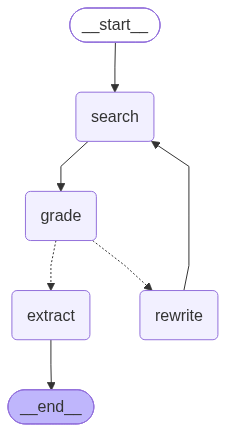

In [16]:
from IPython.display import Image, Markdown, display


def show_graph(graph) -> None:
    # 그래프 구조 시각화 (이미지 생성에 실패하면 Mermaid 텍스트 출력)
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


show_graph(research_subgraph)

### 5.4 병렬 실행: Send API (Fan-out / Fan-in)

4개 Research 축은 서로의 결과가 필요 없으므로 동시에 실행할 수 있다. 이를 위해 LangGraph의 Send API를 사용하며, 전체 흐름은 작업을 나누어 실행한 뒤 결과를 다시 모으는 `Map-Reduce` 구조를 따르도록 하였다.

- Map (Fan-out): Planner 다음의 라우팅 함수(`dispatch_research`)가 `Send("research", 축별 입력)`를 4개 반환한다. LangGraph는 같은 `research` 노드를 축마다 다른 입력으로 동시에 실행한다.
- Reduce (Fan-in): 4개 실행이 모두 끝나면 `merge_dict` Reducer가 축별 결과를 하나의 `research_results`로 합친다. 그다음 Strategy 노드가 한 번 실행된다.

병렬로 실행한다는 점은 기존 설계의 `RunnableParallel`과 같다. 다른 점은 각 Branch 안에 루프(검색 → 평가 → 재검색)가 들어 있다는 것이다. 그래서 축마다 끝나는 시점이 다를 수 있으며, Strategy는 가장 늦게 끝난 축까지 기다린 뒤 시작한다.

`research` 노드는 Subgraph를 실행하고, 결과 중 `AxisResult`와 Trace만 상위 State에 넘긴다. 중간 데이터(탈락 문서, 시도한 검색어 목록 등)는 상위 State로 올라가지 않는다.

축 단위 실패 격리: 4개 `research` 실행은 같은 단계(superstep)에서 함께 돈다. 그래서 한 축에서 예외가 나면 나머지 3축이 이미 끝낸 검색과 LLM 호출까지 함께 버려진다. 이를 막기 위해 `run_research`는 예외를 잡아 신뢰도 '낮음'의 빈 결과를 돌려준다. 이후 Strategy의 신뢰도 규칙과 Data Quality 표가 이 상황을 그대로 반영한다.

In [17]:
def dispatch_research(state: TrendState) -> list[Send]:
    # 4개 축을 각각 다른 입력으로 research 노드에 보낸다
    return [
        Send(
            "research",
            {
                "axis": axis,
                "season": state["season"],
                "brand": state["brand"],
                "season_terms": state["season_terms"],
                "today": state["today"],
                "plan": state["research_plan"][axis],
                "pending_queries": state["research_plan"][axis]["queries"],
                "queries_tried": [],
                "candidates": [],
                "grades": {},
                "attempt": 0,
            },
        )
        for axis in AXES
    ]


def run_research(state: dict) -> dict:
    # Research Subgraph 실행 후 최종 결과와 실행 기록만 상위 그래프로 반환
    axis = state["axis"]
    try:
        output = research_subgraph.invoke(state, config={"recursion_limit": RECURSION_LIMIT})
        return {
            "research_results": {axis: output["result"]},
            "trace": output.get("trace", []),
        }
    except Exception as error:
        # 한 축이 실패해도 나머지 축의 결과는 살린다 (신뢰도 '낮음'의 빈 결과로 진행)
        result = AxisResult(
            axis=axis,
            signal=empty_signal(axis),
            documents=[],
            confidence="낮음",
            data_gaps=state["plan"]["required_aspects"],
            attempts=0,
            queries=[],
        )
        return {
            "research_results": {axis: result},
            "trace": [trace_event("error", f"Research 실패, 빈 결과로 진행 ({error})", axis)],
        }

### 5.5 Strategy Writer

4축 Signal과 요청 프로필을 종합해 상품기획 방향 3개를 작성한다. 기존 Strategy Chain의 역할을 이어받는다.

| 구분 | 기존 설계 | AI Agent 설계 |
|---|---|---|
| 입력 | 검색 원문 Context 4개 | 구조화된 Signal 4개 + RequestProfile + 축별 신뢰도 및 누락 측면 |
| 근거 | 축 단위 참조 번호 | 방향별 `evidence_ids` |
| 재작성 | 없음 | Critic 피드백을 받아 수정 |

프롬프트에 추가한 규칙

- 신뢰도 `낮음`인 축에 주로 의존하는 방향은 `적극 반영`으로 분류하지 않는다.
- 누락 측면(예: 소재 정보 부족)과 관련된 추천은 근거가 약하다는 점을 `caution`에 적는다.
- `RequestProfile`의 중점 상품군과 조건을 반영한다.
- 재작성 모드에서는 Critic이 지적한 문제만 고치고 나머지는 유지한다. 이 규칙이 없으면 재작성 때마다 전체가 바뀌어 새로운 문제가 생기고, 루프가 수렴하지 않는다.
- 적용 수준의 기준을 명시한다. 적극 반영은 runway 및 color 신호가 market이나 브랜드 핵심 상품군에서도 확인될 때만 쓴다. 기준이 모호하면 런웨이 신호가 그대로 '적극 반영'으로 올라간다.
- 세 방향의 역할을 나누고 아이템 중복을 막는다.
- `rationale`은 "어떤 근거에서 → 브랜드의 어떤 특성과 맞고 → 요청을 어떻게 충족하는지" 2~3문장으로 쓰게 한다.

코드가 처리하는 부분

- 근거 축(`signal_sources`)은 코드가 계산한다. LLM이 적은 값을 쓰면 근거 번호와 근거 축이 서로 어긋날 수 있다. 근거 번호 접두어(R/C/M/B)로 다시 계산해 덮어쓴다.
- 4개 축 모두 자료가 없으면 바로 멈춘다. 근거 없이 Strategy와 Critic을 돌려 봐야 의미 없는 리포트만 나온다. 이런 상황은 대부분 API Key나 네트워크 문제다.

In [18]:
import json


def signal_to_text(result: AxisResult) -> str:
    # 축별 Signal을 Strategy 및 Critic 입력용 텍스트로 변환
    lines = [
        f"[{AXIS_LABELS[result.axis]}] 신뢰도: {result.confidence} / "
        f"확인하지 못한 측면: {', '.join(result.data_gaps) or '없음'} / 검색 시도: {result.attempts}회"
    ]
    for name in type(result.signal).model_fields:
        value = getattr(result.signal, name)
        items = value if isinstance(value, list) else [value]
        lines.append(f"- {SIGNAL_FIELD_LABELS.get(name, name)}")
        if not items:
            lines.append("  - 확인된 신호 없음")
        for item in items:
            evidence = ", ".join(item.evidence_ids) or "근거 없음"
            lines.append(f"  - {item.name}: {item.description} (근거: {evidence})")
    return "\n".join(lines)


def all_signals_text(results: dict[str, AxisResult]) -> str:
    return "\n\n".join(signal_to_text(results[axis]) for axis in AXES if axis in results)


def profile_to_text(profile: RequestProfile) -> str:
    return (
        f"- 타깃 고객: {profile.target_customer}\n"
        f"- 중점 상품군: {', '.join(profile.focus_categories) or '없음'}\n"
        f"- 조건: {', '.join(profile.constraints) or '없음'}\n"
        f"- 우선순위: {profile.priority}"
    )


strategy_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
당신은 SPA 패션 브랜드의 다음 시즌 상품기획을 지원하는 전략 담당자입니다.

당신에게는 네 Research 축에서 검증 및 구조화된 Signal이 제공됩니다.
각 Signal 끝의 (근거: R1, C2 ...)는 근거 문서 번호입니다.

[목표]
- 각 축의 핵심 신호를 간결하게 정리하세요.
- 네 축의 공통점과 차이를 연결하세요.
- 적용 수준은 다음 기준으로 정하세요.
  - 적극 반영: runway 및 color 신호가 market 신호나 브랜드 핵심 상품군에서도 확인될 때
  - 선택적 반영: 브랜드 특성과 일부만 맞거나, 한 축에서만 확인될 때
  - 신중 검토: 브랜드 특성과 충돌하거나 근거가 약할 때
- 상품 아이템, 컬러, 소재, 실루엣/디테일 수준까지 구체화하세요.
- 3개의 핵심 상품기획 방향을 제안하세요. 세 방향은 서로 다른 역할을 맡게 하세요.
  (예: 핵심 베이직 강화 / 시즌 트렌드 포인트 / 컬러 및 소재 업데이트)
- 같은 아이템을 여러 방향에 반복하지 마세요.

[근거 규칙]
- 추천하는 아이템, 컬러, 소재, 실루엣은 제공된 Signal에서 확인되는 것만 사용하세요.
  Signal에 없는 소재명이나 컬러명을 일반 상식으로 덧붙이지 마세요.
- 각 방향의 evidence_ids에는 그 방향의 근거가 된 Signal의 문서 번호를 그대로 적으세요.
- 추천 컬러가 있으면 그 컬러의 근거가 된 Color Signal 번호(C로 시작)를 반드시 포함하세요.
- 브랜드와 방향에 맞는 컬러 및 소재가 Signal에 없으면 해당 칸을 비우고, caution에 이유를 적으세요.

[신뢰도 규칙]
- 신뢰도 '낮음'인 축에 주로 의존하는 방향은 '적극 반영'으로 분류하지 마세요.
- 확인하지 못한 측면과 관련된 추천을 할 때는 근거가 약하다는 점을 caution에 적으세요.

[요청 반영]
- 요청 프로필의 타깃 고객, 중점 상품군, 조건을 반영하세요.

[제약]
- 제공된 Signal 밖의 기업 내부 판매 데이터를 상상하지 마세요.
- 확정적인 미래 예측처럼 표현하지 마세요.
- 결과는 한국어로 작성하고, 모든 문장은 '~다'체 평서문으로 쓰세요.
""",
    ),
    (
        "human",
        """
[사용자 입력]
시즌: {season}
브랜드: {brand}
상품기획 요청: {planning_request}

[요청 프로필]
{profile}

[Research Signals]
{signals}
{revision_block}
위 Signal을 함께 분석하여 {brand}의 {season} 상품기획 방향을 작성하세요.
""",
    ),
])

strategy_model = model.with_structured_output(ProductStrategyReport)


def revision_block(state: TrendState) -> str:
    # 재작성 모드일 때만 이전 결과와 Critic 피드백을 넣는다
    critique = state.get("critique")
    report = state.get("report")
    if not critique or critique.passed or not report:
        return ""

    issues = "\n".join(
        f"- [{issue.severity}/{issue.type}] {issue.target}: {issue.detail} → 수정 방법: {issue.fix}"
        for issue in critique.issues
    )
    return f"""
[재작성 모드]
아래는 이전에 작성한 결과와 검토자가 지적한 문제입니다.
- major 문제는 반드시 해결하세요. 근거가 없다고 지적된 값은 삭제하거나 Research Signals에 있는 값으로 교체하세요.
  같은 값을 그대로 다시 쓰면 안 됩니다.
- minor 문제는 가능하면 반영하세요.
- 지적받지 않은 부분은 바꾸지 말고 유지하세요.

[이전 결과]
{report.model_dump_json(indent=2)}

[검토 의견]
{issues}
"""


AXIS_OF_PREFIX = {prefix: axis for axis, prefix in AXIS_PREFIX.items()}


def axes_of(evidence_ids: list[str]) -> list[str]:
    # 근거 번호 접두어(R/C/M/B)로 근거 축을 계산
    used = {AXIS_OF_PREFIX.get(eid[:1]) for eid in evidence_ids}
    return [axis for axis in AXES if axis in used]


def strategy_writer(state: TrendState) -> dict:
    results = state["research_results"]
    if not any(result.documents for result in results.values()):
        # 4개 축 모두 자료가 없으면 전략을 쓸 근거가 없다 (대부분 API Key 및 네트워크 문제)
        raise RuntimeError("모든 Research 축에서 자료를 확보하지 못했습니다. Tavily API Key와 네트워크를 확인하세요.")

    block = revision_block(state)
    is_revision = bool(block)

    report = require(
        strategy_model.invoke(
            strategy_prompt.format_messages(
                season=state["season"],
                brand=state["brand"],
                planning_request=state["planning_request"],
                profile=profile_to_text(state["request_profile"]),
                signals=all_signals_text(state["research_results"]),
                revision_block=block,
            )
        ),
        "Strategy Writer",
    )

    # 근거 축은 LLM이 적은 값 대신 근거 번호로 다시 계산한다
    for direction in report.product_directions:
        direction.signal_sources = axes_of(direction.evidence_ids)

    revision_count = state.get("revision_count", 0) + (1 if is_revision else 0)
    message = f"{revision_count}차 재작성" if is_revision else "초안 작성"
    message += ": " + " / ".join(
        f"{direction.direction_name}({direction.adoption_level})"
        for direction in report.product_directions
    )

    return {
        "report": report,
        "revision_count": revision_count,
        "trace": [trace_event("strategy", message)],
    }

### 5.6 Strategy Critic

Strategy Critic은 Strategy Writer가 작성한 결과를 검토하고, 문제가 있으면 구체적인 수정 지시와 함께 Strategy Writer로 되돌려 보낸다.

이 단계를 따로 둔 이유는 LLM이 결과를 생성하는 도중에는 자신의 오류를 잘 잡아내지 못하기 때문이다. 같은 결과라도 별도 단계에서 평가자 역할을 맡기면 상당 부분을 찾아낼 수 있다. 상품기획 리포트에서 가장 위험한 오류는 근거 자료에 없는 컬러나 소재를 그럴듯하게 추천하는 것이므로, 생성이 끝난 뒤 이를 따로 검사한다.

이 단계에서 사용한 기법은 다음과 같다.

- Reflection / Self-Critique: 생성한 결과를 다시 검토한다.
- Evaluator-Optimizer 패턴: 생성자(Writer)와 평가자(Critic)를 분리해 반복한다.
- LLM-as-a-Judge: LLM에게 정해진 기준으로 결과를 채점하게 한다.

검사는 두 층으로 나눈다. 코드로 확인할 수 있는 항목은 규칙 검사로 먼저 처리하고, 해석이 필요한 항목은 LLM이 의미 검사로 판단한다. 두 검사에서 나온 문제를 합쳐 major가 하나라도 있으면 통과하지 못한다.

1) 규칙 검사 (코드)

| 검사 | 심각도 |
|---|---|
| 방향이 정확히 3개인가 | major |
| 모든 방향에 근거 번호가 있고, 실제 문서 번호인가 | major |
| 추천 컬러가 있으면 Color 근거 번호(C)가 있는가 (Color Signal이 있을 때만) | major |
| 추천 아이템이 비어 있지 않은가 (근거가 될 Signal이 있을 때만) | major |
| 추천 컬러 및 소재가 비어 있지 않은가 (근거가 될 Signal이 있을 때만) | minor |
| '적극 반영'인데 Market 및 Brand 근거가 없는가 | minor |
| 같은 아이템이 여러 방향에 반복되는가 | minor |

일부 항목에는 "근거가 될 Signal이 있을 때만"이라는 조건을 붙였다. 예를 들어 Color 축 검색이 실패해 Color Signal이 비어 있으면, 근거 있는 컬러를 추천할 방법이 없다. 이 상황에서도 컬러를 요구하면 Strategy는 근거 없는 값을 채우거나, 매번 재작성 한도까지 실패하게 된다.

컬러 및 소재의 빈 칸을 minor로 둔 것도 같은 이유다. 처음 구현에서는 이를 major로 두었는데, Runway의 소재 신호가 레이스 및 시어 소재뿐이었을 때 베이직 중심 브랜드에 맞는 소재가 없었다. 그러자 Strategy는 칸을 채우려고 Signal에 없는 소재를 쓰고, Critic은 이를 근거 없음으로 지적하는 일이 반복되어 재작성이 한도까지 이어졌다. 브랜드에 맞는 신호가 없다면 칸을 비워 두고 caution에 이유를 적는 편이 상품기획 판단으로도 정직하다.

다만 규칙 검사는 근거 번호의 형식과 정합성만 확인한다. Strategy가 관련 없는 C 번호를 붙여 통과하는 경우는 막지 못하므로, 추천값이 실제로 Signal에 있는지는 이어지는 의미 검사의 grounding 항목에서 확인한다.

2) 의미 검사 (LLM)

| 검사 항목 | 확인 내용 |
|---|---|
| grounding | 추천 아이템, 컬러, 소재, 실루엣이 Signal에 실제로 존재하는가 |
| brand_fit | 적용 수준이 Brand Profile과 모순되지 않는가 |
| request_fit | 요청 프로필의 중점 상품군과 조건을 반영했는가 |
| overclaim | 전망을 확정된 사실처럼 표현하지 않았는가 |
| confidence | 신뢰도가 낮은 축에 기반한 방향을 과하게 평가하지 않았는가 |

Critic의 LLM 호출이 실패하면 규칙 검사 결과만으로 판정하고, 그 사실을 리포트의 Review Notes에 남긴다.

3) 루프가 수렴하도록 둔 장치

LLM 평가자는 재작성된 결과를 볼 때마다 새로운 지적을 찾아내는 경향이 있다. 이 경우 Strategy가 지적을 고쳐도 다른 지적이 생겨, 재작성이 매번 최대 횟수까지 반복된다. 이를 막기 위해 두 가지 장치를 두었다.

- LLM 판정에서 나오는 major는 늘리지 않는다. 코드 규칙은 같은 입력에 항상 같은 판정을 내리고, 한 번 고치면 다시 걸리지 않으므로 루프 수렴을 해치지 않는다. 반면 LLM 판정은 재작성본마다 새로운 지적을 만들 수 있다. 그래서 LLM이 major로 보고할 수 있는 경우를 근거 없는 추천, 신뢰도 규칙 위반, 브랜드 및 요청과의 정면 모순으로 제한하였다. 가격 및 공정 추정이나 대안 제시처럼 내부 데이터 없이 판단하기 어려운 의견은 minor로 보고하게 했다.
- 재작성 결과를 검토할 때는 이전 major 지적을 함께 전달한다. Critic은 먼저 이전 지적이 해결되었는지 확인하고, 새로운 major는 기준에 명확히 해당할 때만 보고한다.

In [19]:
critic_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
당신은 SPA 브랜드 상품기획 리포트를 검토하는 시니어 MD입니다.
작성된 상품기획 방향이 근거 Signal과 요청에 맞는지 검토하고, 문제를 찾아 issues로 보고하세요.

[검사 항목]
- grounding: 추천 아이템, 컬러, 소재, 실루엣/디테일이 Research Signals에 실제로 등장하는가.
  Runway, Color, Market, Brand 중 어느 Signal에든 등장하면 근거가 있는 것으로 봅니다.
  (예: Brand Profile에 나온 브랜드 고유 소재는 근거가 있다.)
  어느 Signal에도 없는 컬러, 소재, 아이템이 추천되었다면 major입니다.
- brand_fit: 적용 수준(적극 반영/선택적 반영/신중 검토)이 Brand Profile과 모순되지 않는가.
- request_fit: 요청 프로필의 타깃 고객, 중점 상품군, 조건이 반영되었는가.
- overclaim: 전망을 확정된 사실처럼 표현했는가.
- confidence: 신뢰도 '낮음'인 축에 주로 의존하는 방향을 '적극 반영'으로 분류했는가.

[심각도 기준]
- major는 다음 경우에만 사용하세요.
  - grounding: Signal에 없는 아이템, 컬러, 소재, 실루엣이 추천됨
  - confidence: 신뢰도 '낮음' 축에 주로 의존하는 방향이 '적극 반영'으로 분류됨
  - brand_fit / request_fit: Brand Profile이나 요청 프로필과 정면으로 모순됨 (예: 베이직 중심 브랜드에 실험적 실루엣을 '적극 반영')
- 가격, 공정, 생산 가능성에 대한 추정, 더 나은 대안이 있다는 의견, 표현 개선은 minor로 보고하세요.
  기업 내부 데이터 없이 판단하기 어려운 내용이기 때문입니다.

[보고 규칙]
- target은 direction_1.recommended_colors처럼 위치를 적으세요. (방향 번호는 1부터)
- fix에는 어떻게 고쳐야 하는지 구체적으로 적으세요.
- 문제가 없으면 issues를 빈 리스트로 두세요. 문제를 억지로 만들지 마세요.
- 한국어로 작성하세요.
""",
    ),
    (
        "human",
        """
[요청 프로필]
{profile}

[Research Signals]
{signals}

[검토할 상품기획 방향]
{directions}
{previous_block}""",
    ),
])

critic_model = judge_model.with_structured_output(CriticReview)


# 추천 필드별로 근거가 될 수 있는 Signal (축, 필드)
FIELD_SIGNALS = {
    "recommended_items": [("runway", "key_items"), ("market", "trending_styles"), ("brand", "core_categories")],
    "recommended_colors": [("color", "key_colors")],
    "recommended_materials": [("runway", "materials")],
}
FIELD_LABELS = {
    "recommended_items": "추천 아이템",
    "recommended_colors": "추천 컬러",
    "recommended_materials": "추천 소재",
}


def signal_available(results: dict[str, AxisResult], field: str) -> bool:
    # 이 추천 필드의 근거가 될 Signal 값이 하나라도 있는가
    return any(
        axis in results and getattr(results[axis].signal, name)
        for axis, name in FIELD_SIGNALS[field]
    )


def rule_check(state: TrendState) -> list[Issue]:
    # LLM 없이 확인할 수 있는 형식 및 근거 번호 검사 (같은 입력에는 항상 같은 판정)
    report: ProductStrategyReport = state["report"]
    results = state["research_results"]
    known_ids = {doc["doc_id"] for result in results.values() for doc in result.documents}
    issues = []

    if len(report.product_directions) != 3:
        issues.append(Issue(
            target="product_directions",
            type="format",
            severity="major",
            detail=f"상품기획 방향이 {len(report.product_directions)}개입니다.",
            fix="상품기획 방향을 정확히 3개로 작성하세요.",
        ))

    seen_items: dict[str, int] = {}

    for index, direction in enumerate(report.product_directions, start=1):
        sources = axes_of(direction.evidence_ids)

        # 근거 번호 존재 여부
        if not direction.evidence_ids:
            issues.append(Issue(
                target=f"direction_{index}.evidence_ids",
                type="grounding",
                severity="major",
                detail="근거 문서 번호가 없습니다.",
                fix="Signal에 표시된 근거 문서 번호를 evidence_ids에 적으세요.",
            ))
        unknown = [eid for eid in direction.evidence_ids if eid not in known_ids]
        if unknown:
            issues.append(Issue(
                target=f"direction_{index}.evidence_ids",
                type="grounding",
                severity="major",
                detail=f"존재하지 않는 근거 번호가 있습니다: {', '.join(unknown)}",
                fix="Signal에 실제로 표시된 문서 번호만 사용하세요.",
            ))

        # 추천 컬러가 있는데 Color 근거 번호가 없는 경우 (Color Signal이 있을 때만)
        if direction.recommended_colors and "color" not in sources and signal_available(results, "recommended_colors"):
            issues.append(Issue(
                target=f"direction_{index}.evidence_ids",
                type="grounding",
                severity="major",
                detail="추천 컬러가 있지만 Color 근거 번호(C)가 없습니다.",
                fix="추천 컬러의 근거가 된 Color Signal 번호(C)를 evidence_ids에 추가하세요.",
            ))

        # 추천 필드가 비어 있는 경우 (근거가 될 Signal이 있을 때만 문제로 본다)
        # 아이템은 상품기획의 핵심이라 major, 컬러 및 소재는 브랜드에 맞는 신호가 없을 수 있어 minor
        for field, label in FIELD_LABELS.items():
            if not getattr(direction, field) and signal_available(results, field):
                issues.append(Issue(
                    target=f"direction_{index}.{field}",
                    type="format",
                    severity="major" if field == "recommended_items" else "minor",
                    detail=f"{label}가 비어 있습니다.",
                    fix=f"Signal에 근거한 {label}를 작성하거나, 비워 둔 이유를 caution에 적으세요.",
                ))

        # 적극 반영인데 시장 및 브랜드 근거가 없는 경우 (minor)
        if direction.adoption_level == "적극 반영" and not ({"market", "brand"} & set(sources)):
            issues.append(Issue(
                target=f"direction_{index}.adoption_level",
                type="brand_fit",
                severity="minor",
                detail="적극 반영이지만 Market 및 Brand 근거 번호가 없습니다.",
                fix="Market 또는 Brand 근거를 추가하거나 적용 수준을 선택적 반영으로 낮추세요.",
            ))

        # 같은 아이템이 여러 방향에 반복되는 경우 (minor)
        for item in direction.recommended_items:
            key = item.strip()
            if key in seen_items and seen_items[key] != index:
                issues.append(Issue(
                    target=f"direction_{index}.recommended_items",
                    type="format",
                    severity="minor",
                    detail=f"'{key}'가 direction_{seen_items[key]}에도 있습니다.",
                    fix="방향마다 서로 다른 아이템을 제안하세요.",
                ))
            seen_items.setdefault(key, index)

    return issues


def directions_to_text(report: ProductStrategyReport) -> str:
    return json.dumps(
        [direction.model_dump() for direction in report.product_directions],
        ensure_ascii=False,
        indent=2,
    )


def previous_issues_block(state: TrendState) -> str:
    # 재작성 결과를 검토할 때는 이전 major 지적을 함께 보여주고, 해결 여부를 먼저 확인하게 한다
    critique = state.get("critique")
    if not critique or critique.passed:
        return ""
    majors = [issue for issue in critique.issues if issue.severity == "major"]
    if not majors:
        return ""
    lines = "\n".join(f"- {issue.target}: {issue.detail}" for issue in majors)
    return f"""
[이전 검토의 major 지적]
{lines}

이번 결과는 위 지적을 반영해 재작성한 것입니다.
먼저 위 지적이 해결되었는지 확인하고, 해결되지 않았다면 다시 major로 보고하세요.
새로운 major는 심각도 기준에 명확히 해당할 때만 보고하세요.
"""


def strategy_critic(state: TrendState) -> dict:
    rule_issues = rule_check(state)

    try:
        review = require(
            critic_model.invoke(
                critic_prompt.format_messages(
                    profile=profile_to_text(state["request_profile"]),
                    signals=all_signals_text(state["research_results"]),
                    directions=directions_to_text(state["report"]),
                    previous_block=previous_issues_block(state),
                )
            ),
            "Strategy Critic",
        )
        llm_issues, llm_reviewed = review.issues, True
    except Exception:
        # LLM 검토가 실패하면 규칙 검사 결과만으로 판정한다
        llm_issues, llm_reviewed = [], False

    issues = rule_issues + llm_issues
    major = [issue for issue in issues if issue.severity == "major"]
    critique = Critique(passed=not major, issues=issues, llm_reviewed=llm_reviewed)

    if critique.passed:
        decision = "통과"
    elif state.get("revision_count", 0) < MAX_REVISIONS:
        decision = "재작성 요청"
    else:
        decision = "수정 한도 도달, 남은 문제를 리포트에 표시"

    message = f"검토: major {len(major)}건, minor {len(issues) - len(major)}건 → {decision}"
    if not llm_reviewed:
        message += " [LLM 검토 실패, 규칙 검사만 적용]"
    if major:
        message += " (" + "; ".join(f"{issue.target}: {issue.detail}" for issue in major) + ")"
    return {"critique": critique, "trace": [trace_event("critic", message)]}

#### 5.6.1 Critic 라우팅

Critic의 검토 결과에 따라 다음 단계가 정해진다. 이 분기는 LLM이 아니라 라우팅 함수(`route_after_critic`)가 고정된 규칙으로 결정한다.

```text
passed                                   → report
not passed 그리고 revision_count < 2     → strategy (Critic 피드백 전달)
not passed 그리고 한도 도달               → report (남은 문제를 '검토 필요 사항'으로 표시)
```

검토를 통과하면 리포트 작성으로 넘어간다. 통과하지 못했더라도 재작성 횟수가 남아 있으면 Critic의 피드백과 함께 Strategy Writer로 돌아가고, 한도에 도달했다면 남은 문제를 리포트에 '검토 필요 사항'으로 표시한 채 마무리한다.

근거가 부족하다는 지적을 받았을 때 Research 단계로 돌아가 추가 검색을 하는 설계도 생각할 수 있다. 그러나 이번 설계에서는 Strategy Writer로만 되돌린다. 그 이유는 다음과 같다.

- Research 단계에서 이미 축별로 재검색 루프를 거쳤으므로, 거기서 찾지 못한 정보를 다시 찾을 가능성이 낮다.
- 루프가 두 겹(Critic → Research → Strategy → Critic)이 되면 호출 수와 실행 경로가 크게 늘어나 뼈대 고정 원칙에 어긋난다.
- 근거가 부족한 방향은 자료를 더 찾기보다 적용 수준을 낮추거나 다른 방향으로 바꾸는 편이 상품기획 판단으로서 더 정직하다.

최대 재작성 횟수는 2회로 두었다. Evaluator-Optimizer 루프는 대부분 1~2회 안에 개선 폭이 줄어들며, 그 이상 반복하면 비용만 늘어나고 사소한 지적이 되풀이되기 때문이다.

In [20]:
def route_after_critic(state: TrendState) -> Literal["strategy", "report"]:
    if state["critique"].passed:
        return "report"
    if state.get("revision_count", 0) < MAX_REVISIONS:
        return "strategy"
    return "report"

### 5.7 Report Builder

최종 State를 Markdown 리포트로 변환한다. 리포트 형식은 정해져 있고 내용은 이미 Structured Output으로 확보되어 있으므로 LLM을 쓰지 않는다. 여기서 LLM을 다시 부르면 내용이 바뀔 위험만 생긴다.

기존 리포트 구성에 다음 섹션을 추가한다.

| 섹션 | 내용 |
|---|---|
| Research Findings의 Signal 목록 | 요약 문단 아래에 Signal 추출 결과를 근거 번호와 함께 그대로 출력 (기존 설계는 LLM 요약에 축 전체 번호를 일괄로 붙임) |
| 방향별 근거 | 각 Strategy 블록에 `근거 자료: [3] [7]` 표시 (기존 설계는 축 단위) |
| Data Quality | 축별 신뢰도(자료 충분도), Signal 추출에 사용한 문서 수, 검색 시도 횟수, 확인하지 못한 측면 |
| Review Notes | Critic 검토 결과와, 한도 도달 시 해결되지 않은 문제 |
| Agent Trace | 축별 검색, 평가, 재검색 과정과 Strategy 및 Critic 반복 기록 |

References에는 Signal이나 상품기획 방향이 실제로 인용한 문서만 넣는다. 리포트 헤더의 시즌 및 브랜드도 LLM 출력이 아니라 사용자 입력(State)을 그대로 쓴다.

Agent는 실행마다 경로가 달라질 수 있어, 결과만 보면 "왜 이런 추천이 나왔는지", "Color 자료가 왜 적은지"를 알 수 없다. 그래서 리포트에 Agent Trace를 함께 넣었다. 사용자는 이를 보고 리포트를 얼마나 믿을지 스스로 판단할 수 있고, 개발 단계에서는 어느 노드의 판단이 잘못되었는지 찾을 수 있다.

In [21]:
def collect_references(results: dict[str, AxisResult], cited_ids: set[str]) -> tuple[list[dict], dict[str, int]]:
    # 리포트에서 실제로 인용한 문서만 참고문헌으로 모으고, 문서 번호 → 참조 번호 매핑을 만든다
    references: list[dict] = []
    url_to_number: dict[str, int] = {}
    id_to_number: dict[str, int] = {}

    for axis in AXES:
        if axis not in results:
            continue
        for doc in results[axis].documents:
            if doc["doc_id"] not in cited_ids:
                continue
            url = doc["url"]
            if url in url_to_number:
                number = url_to_number[url]
            else:
                number = len(references) + 1
                url_to_number[url] = number
                references.append({**doc, "number": number, "category": AXIS_LABELS[axis]})
            id_to_number[doc["doc_id"]] = number

    return references, id_to_number


def citation_text(evidence_ids: list[str], id_to_number: dict[str, int]) -> str:
    numbers = sorted({id_to_number[eid] for eid in evidence_ids if eid in id_to_number})
    return " ".join(f"[{number}]" for number in numbers) if numbers else "근거 자료 없음"


def signal_evidence_ids(result: AxisResult) -> list[str]:
    ids = []
    for name in type(result.signal).model_fields:
        value = getattr(result.signal, name)
        for item in value if isinstance(value, list) else [value]:
            ids.extend(item.evidence_ids)
    return ids


def signal_bullets(result: AxisResult, id_to_number: dict[str, int]) -> str:
    # Extract 결과를 LLM 없이 그대로 출력 (근거 번호가 붙은 문장은 모두 Signal 원문)
    lines = []
    for name in type(result.signal).model_fields:
        value = getattr(result.signal, name)
        for item in value if isinstance(value, list) else [value]:
            if item.evidence_ids:
                lines.append(
                    f"- **{SIGNAL_FIELD_LABELS.get(name, name)}** {item.name}: {item.description} "
                    f"{citation_text(item.evidence_ids, id_to_number)}"
                )
    return "\n".join(lines) or "- 확인된 신호 없음"


def references_markdown(references: list[dict]) -> str:
    if not references:
        return "사용된 자료가 없다."
    lines = []
    for item in references:
        date_text = f", {item['published_date']}" if item["published_date"] else ""
        lines.append(f"{item['number']}. [{item['title']}]({item['url']}) — {item['category']}{date_text}")
    return "\n".join(lines)


def data_quality_markdown(results: dict[str, AxisResult]) -> str:
    rows = [
        "| Research | 신뢰도 | Signal 추출에 사용한 문서 | 검색 시도 | 확인하지 못한 측면 |",
        "|---|---|---|---|---|",
    ]
    for axis in AXES:
        result = results[axis]
        rows.append(
            f"| {AXIS_LABELS[axis]} | {result.confidence} | {len(result.documents)}건 | "
            f"{result.attempts}회 | {', '.join(result.data_gaps) or '없음'} |"
        )
    rows.append("")
    rows.append("*신뢰도는 유효 문서 수와 필수 측면 확인 여부로 코드가 계산한 자료 충분도이며, 출처의 공신력은 반영하지 않는다.*")
    return "\n".join(rows)


def review_notes_markdown(critique: Critique, revision_count: int) -> str:
    if not critique.llm_reviewed:
        prefix = "*Critic의 LLM 검토가 실패해 규칙 검사만 적용했다.*\n\n"
    else:
        prefix = ""
    return prefix + review_body(critique, revision_count)


def review_body(critique: Critique, revision_count: int) -> str:
    if critique.passed:
        text = f"Critic 검토를 통과했다. (재작성 {revision_count}회)"
        minor = [issue for issue in critique.issues if issue.severity == "minor"]
        if minor:
            text += "\n\n참고 의견:\n" + "\n".join(f"- {issue.target}: {issue.detail}" for issue in minor)
        return text

    lines = [f"재작성 {revision_count}회 후에도 해결되지 않은 문제가 있어 **검토가 필요하다.**", ""]
    for issue in critique.issues:
        if issue.severity == "major":
            lines.append(f"- **{issue.target}** ({issue.type}): {issue.detail}")
    return "\n".join(lines)


def trace_markdown(trace: list[dict]) -> str:
    # 병렬 실행으로 섞인 기록을 단계 및 축 순서로 정리
    lines = []
    for event in trace:
        if event["step"] in ("normalizer", "planner"):
            lines.append(f"- **{event['step'].capitalize()}**: {event['message']}")

    for axis in AXES:
        events = [event for event in trace if event["axis"] == axis]
        if events:
            lines.append(f"- **{AXIS_LABELS[axis]}**")
            lines.extend(f"  - {event['message']}" for event in events)

    for event in trace:
        if event["step"] in ("strategy", "critic"):
            lines.append(f"- **{event['step'].capitalize()}**: {event['message']}")
    return "\n".join(lines)


def report_builder(state: TrendState) -> dict:
    report: ProductStrategyReport = state["report"]
    results = state["research_results"]

    cited_ids = {eid for result in results.values() for eid in signal_evidence_ids(result)}
    cited_ids |= {eid for direction in report.product_directions for eid in direction.evidence_ids}
    references, id_to_number = collect_references(results, cited_ids)

    insights = [
        ("runway", report.runway_insight),
        ("color", report.color_insight),
        ("market", report.current_market_insight),
        ("brand", report.brand_insight),
    ]
    research_sections = [
        f"### {index}. {AXIS_LABELS[axis]} (신뢰도: {results[axis].confidence})\n\n"
        f"**요약** {text}\n\n"
        f"{signal_bullets(results[axis], id_to_number)}"
        for index, (axis, text) in enumerate(insights, start=1)
    ]

    direction_blocks = []
    for index, direction in enumerate(report.product_directions, start=1):
        direction_blocks.append(
            f"### Strategy {index}. {direction.direction_name}\n\n"
            f"| 항목 | 내용 |\n"
            f"|---|---|\n"
            f"| **적용 수준** | {direction.adoption_level} |\n"
            f"| **추천 아이템** | {', '.join(direction.recommended_items)} |\n"
            f"| **추천 컬러** | {', '.join(direction.recommended_colors)} |\n"
            f"| **추천 소재** | {', '.join(direction.recommended_materials)} |\n"
            f"| **실루엣 / 디테일** | {', '.join(direction.silhouette_or_detail)} |\n"
            f"| **근거 축** | {', '.join(AXIS_LABELS[source] for source in direction.signal_sources)} |\n\n"
            f"**전략 판단 근거**  \n{direction.rationale}\n\n"
            f"**적용 시 고려사항**  \n{direction.caution}\n\n"
            f"*근거 자료: {citation_text(direction.evidence_ids, id_to_number)}*"
        )

    final_markdown = f"""
# Fashion Trend & Product Strategy Report

> **Season:** {state["season"]}
> **Brand:** {state["brand"]}
> **Planning Request:** {state["planning_request"]}

---

## 1. Executive Summary

{report.executive_summary}

---

## 2. Research Findings

네 Research 축에서 검증 및 구조화한 Signal이다. **요약**은 Strategy 단계에서 작성한 해석이고, 그 아래 목록은 Signal 추출 결과를 그대로 옮긴 것이다. 각 항목의 근거는 리포트 마지막 References에서 번호로 확인할 수 있다.

{(chr(10) * 2).join(research_sections)}

---

## 3. Integrated Analysis

{report.signal_connection}

---

## 4. Strategic Product Directions

{(chr(10) * 2).join(direction_blocks)}

---

## 5. Management Considerations

{report.final_note}

---

## 6. Data Quality

{data_quality_markdown(results)}

---

## 7. Review Notes

{review_notes_markdown(state["critique"], state.get("revision_count", 0))}

---

## 8. Agent Trace

{trace_markdown(state.get("trace", []))}

---

## References

{references_markdown(references)}

---

### Report Scope

본 리포트는 공개 웹 검색을 통해 수집하고 Agent가 검증한 외부 정보를 기반으로 작성되었다.
실제 상품기획 의사결정에서는 판매 실적, 재고, 원가, 마진, 고객 데이터 등 기업 내부 데이터와 함께 검토해야 한다.
"""
    return {"final_markdown": final_markdown}

### 5.8 전체 그래프 조립

```text
START → normalizer → planner ─(Send ×4)→ research → strategy → critic ─┬→ report → END
                                                        ▲               │
                                                        └── 재작성 ──────┘
```

- `planner → research`: `dispatch_research`가 `Send` 4개를 반환하는 Conditional Edge (Fan-out)
- `research → strategy`: 고정 Edge. 4개 `research` 실행이 모두 끝난 뒤 한 번 실행된다 (Fan-in)
- `critic → strategy | report`: `route_after_critic`이 정하는 Conditional Edge (Critic 루프)

TrendWeave Agent 그래프 구성 완료


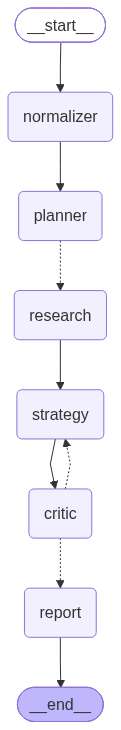

In [22]:
builder = StateGraph(TrendState)

builder.add_node("normalizer", input_normalizer)
builder.add_node("planner", research_planner)
builder.add_node("research", run_research)
builder.add_node("strategy", strategy_writer, retry_policy=LLM_RETRY)
builder.add_node("critic", strategy_critic)  # LLM 실패는 노드 안에서 처리
builder.add_node("report", report_builder)

builder.add_edge(START, "normalizer")
builder.add_edge("normalizer", "planner")
builder.add_conditional_edges("planner", dispatch_research, ["research"])
builder.add_edge("research", "strategy")
builder.add_edge("strategy", "critic")
builder.add_conditional_edges("critic", route_after_critic, ["strategy", "report"])
builder.add_edge("report", END)

trend_agent = builder.compile()

print("TrendWeave Agent 그래프 구성 완료")
show_graph(trend_agent)

In [23]:
def analyze_product_strategy(season: str, brand: str, planning_request: str) -> dict:
    # 전체 Agent 실행. 반환값은 최종 State (final_markdown, report, research_results, trace 등)
    return trend_agent.invoke(
        {
            "season": season,
            "brand": brand,
            "planning_request": planning_request,
        },
        config={"recursion_limit": RECURSION_LIMIT},
    )

### 5.9 Gradio UI

분석 브랜드는 UNIQLO로 고정한다. 사용자는 분석 시즌과 상품기획 요청만 입력하며, 브랜드는 화면에 표시만 되고 바꿀 수 없다.

리포트 생성 버튼을 누르면 Agent가 작성한 리포트가 화면에 표시된다. 리포트 하단의 Data Quality와 Agent Trace에서 Agent가 어떤 판단을 거쳤는지 확인할 수 있다.

In [24]:
import gradio as gr

# 분석 브랜드 고정
BRAND = "UNIQLO"

DEFAULT_PLANNING_REQUEST = (
    "한국의 20-30대 고객이 일상에서 활용하기 쉬운 상품 중심으로 기획해줘."
)


def run_gradio_analysis(season: str, planning_request: str) -> str:
    try:
        result = analyze_product_strategy(season, BRAND, planning_request)
        return result["final_markdown"]
    except Exception as error:
        return f"## 분석 중 오류가 발생했습니다\n\n`{error}`"


with gr.Blocks(title="TrendWeave Agent") as demo:
    gr.Markdown(
        f"""
        # TrendWeave Agent
        ### Next-Season Product Strategy Agent for {BRAND}

        요청을 해석해 Runway, Color Forecast, Current Market, Brand Context를 병렬로 조사하고,
        자료가 부족하면 스스로 다시 검색한 뒤 검토를 거친 상품기획 전략 리포트를 생성합니다.
        """
    )

    with gr.Row():
        season_input = gr.Textbox(label="분석 시즌", value="2027 S/S", placeholder="예: 2027 S/S")
        gr.Textbox(label="분석 브랜드 (고정)", value=BRAND, interactive=False)

    planning_request_input = gr.Textbox(
        label="상품기획 요청",
        value=DEFAULT_PLANNING_REQUEST,
        placeholder="상품기획 시 중요하게 보고 싶은 조건을 자유롭게 입력하세요.",
        lines=3,
    )

    gr.Markdown(
        """
        Agent Flow: `요청 해석 → 4축 병렬 조사(평가 및 재검색) → 전략 작성 ↔ 검토 → 리포트`

        분석에는 2~4분 정도 걸립니다. (무료 등급 호출 한도에 맞춰 속도를 제한함)
        """
    )

    with gr.Row():
        analyze_button = gr.Button("리포트 생성", variant="primary")
        clear_button = gr.ClearButton(
            components=[season_input, planning_request_input],
            value="입력 초기화",
        )

    report_output = gr.Markdown(value="분석을 실행하면 전략 리포트가 이 영역에 표시됩니다.")

    analyze_button.click(
        fn=run_gradio_analysis,
        inputs=[season_input, planning_request_input],
        outputs=report_output,
    )

    gr.Examples(
        examples=[
            ["2027 S/S", DEFAULT_PLANNING_REQUEST],
            ["2027 S/S", "데님 상품군 중심으로, 여름에도 입기 좋은 가벼운 소재 위주로 기획해줘."],
        ],
        inputs=[season_input, planning_request_input],
    )

demo.launch(show_error=True)

/Users/minchae/Desktop/workspace/SKALA/working/21_ai_agent/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


### 5.10 기능 테스트

기존 설계에서 하던 브랜드 A/B 비교 테스트는 이번 범위에서 제외했다. 대신 UNIQLO 한 브랜드를 기준으로 **Agent의 판단이 실제로 작동하는지** 확인한다.

| 테스트 | 입력 | 확인할 것 |
|---|---|---|
| 5.10.1 기본 실행 | 2027 S/S, UNIQLO, 기본 요청 | 그래프가 끝까지 실행되고 리포트의 모든 섹션이 채워지는가 |
| 5.10.2 요청 반영 | 같은 시즌 및 브랜드, 기본 요청 vs "데님 중심" 요청 | Planner의 검색어와 요청 프로필이 달라지는가 |
| 5.10.3 재검색 동작 | 자료가 적은 먼 시즌 (2028 F/W) Runway | Rewrite가 일어나고 Trace에 이유가 남는가 |
| 5.10.4 문서 평가 | 시즌이 다른 문서와 쇼핑몰 문서가 섞인 경우 | Grade가 해당 문서를 탈락시키는가 |
| 5.10.5 Critic 동작 | 근거 없는 컬러를 일부러 넣은 결과 | Critic이 grounding 문제로 잡아내는가 |
| 5.10.6 규칙 검사 | Color 근거 번호를 뺀 결과 / Color Signal이 빈 상황 | 앞의 경우는 major, 뒤의 경우는 컬러 관련 major가 없어야 한다 (API 호출 없음) |

5.10.2~5.10.6은 전체 그래프가 아니라 **노드나 Subgraph를 단독으로 실행**한다. 노드를 나눠 두었기 때문에 필요한 부분만 따로 검증할 수 있고, API 호출도 줄어든다.

실제 웹 검색과 LLM 호출이 발생하므로 `RUN_AGENT_TESTS`로 실행 여부를 제어한다.

In [25]:
RUN_AGENT_TESTS = True

basic_case = {
    "season": "2027 S/S",
    "brand": "UNIQLO",
    "planning_request": "한국의 20-30대 고객이 일상에서 활용하기 쉬운 상품 중심으로 기획해줘.",
}

#### 5.10.1 기본 실행

전체 그래프를 실행하고 최종 리포트를 출력한다.

In [26]:
if RUN_AGENT_TESTS:
    result_basic = analyze_product_strategy(**basic_case)
    display(Markdown(result_basic["final_markdown"]))
else:
    print("RUN_AGENT_TESTS = False 이므로 테스트를 건너뛴다.")


# Fashion Trend & Product Strategy Report

> **Season:** 2027 S/S
> **Brand:** UNIQLO
> **Planning Request:** 한국의 20-30대 고객이 일상에서 활용하기 쉬운 상품 중심으로 기획해줘.

---

## 1. Executive Summary

UNIQLO의 2027 S/S 시즌은 브랜드의 핵심인 '라이프웨어' 철학을 유지하면서, 런웨이와 마켓에서 확인된 편안하고 여유로운 실루엣과 따뜻한 뉴트럴 컬러 팔레트를 결합하여 일상 속 실용성을 극대화하는 방향으로 기획한다.

---

## 2. Research Findings

네 Research 축에서 검증 및 구조화한 Signal이다. **요약**은 Strategy 단계에서 작성한 해석이고, 그 아래 목록은 Signal 추출 결과를 그대로 옮긴 것이다. 각 항목의 근거는 리포트 마지막 References에서 번호로 확인할 수 있다.

### 1. Runway Research (신뢰도: 높음)

**요약** 드레이핑과 슬라우치 팬츠 등 여유로운 실루엣이 강조되며, 시어 소재와 레이스 디테일이 가벼운 무드를 형성한다.

- **실루엣** 드레이핑 실루엣(Draping silhouettes): 로맨틱한 분위기를 강조하기 위해 정교한 드레이핑 기법을 활용한 실루엣이 나타났다. [1]
- **실루엣** 가볍고 유연한 실루엣(Languid, gossamer silhouettes): 신체와 밀착되면서도 가볍고 관능적인 느낌을 주는 유연한 실루엣이 강조되었다. [5]
- **실루엣** 슬라우치 팬츠(Slouchy pants): 편안하고 여유로운 핏의 슬라우치 팬츠가 런웨이에 등장했다. [2]
- **소재** 레이스(Lace): 기퓌르 레이스(guipure lace)를 비롯해 의류 밑단이나 드레스 등에 섬세한 레이스 디테일이 다양하게 활용되었다. [1] [2] [3] [6]
- **소재** 금속성 소재(Metallic fabrics): 라메(lamé), 메탈릭 코튼(metallic cotton) 등 금빛 광택이 도는 다양한 소재가 사용되었다. [3]
- **소재** 시어 및 필름 소재(Sheer and filmy fabrics): 오간자(organza), 시폰(chiffon), 튤(tulle) 등 비치거나 가벼운 질감의 소재가 컬렉션 전반에 나타났다. [1] [3] [5]
- **소재** 데님(Denim): 해체된 데님(shredded denim)이나 트롱프뢰유(trompe-l’œil) 프린트 등 데님을 활용한 다양한 변주가 돋보였다. [6]
- **디테일** 주름 및 텍스처 디테일(Crinkled, pleated and ruffled textures): 원단에 주름을 잡거나 러플을 더해 입체적인 텍스처를 강조하는 디테일이 사용되었다. [3]
- **디테일** 컷아웃 및 슬릿(Sheer inserts and shredded details): 시어한 소재를 덧대거나 원단을 잘게 찢어 레이스처럼 보이게 하는 기법이 활용되었다. [1] [6]
- **디테일** 프린트 및 자수(Hand-painted prints and embroideries): 수작업으로 그린 프린트나 정교한 자수 장식이 컬렉션의 완성도를 높였다. [1] [5]
- **핵심 아이템** 슬립 드레스(Slip dresses): 란제리 스타일에서 영감을 받은 관능적인 슬립 드레스가 주요 아이템으로 등장했다. [2] [5]
- **핵심 아이템** 테일러드 재킷 및 수트(Tailored jackets and suits): 오프숄더 블레이저, 사파리 재킷, 새틴 팬츠 수트 등 변형된 테일러링 아이템이 주목받았다. [2] [3] [4]
- **핵심 아이템** 쇼츠 및 핫팬츠(Short-shorts and HotPants): 길이가 짧은 쇼츠와 매우 짧은 핫팬츠가 스포티하거나 파격적인 스타일로 제안되었다. [2] [6]
- **핵심 아이템** 트렌치코트(Trenchcoats): 클래식한 아이템인 트렌치코트가 다양한 소재와 결합되어 새롭게 해석되었다. [3]

### 2. Color Forecast Research (신뢰도: 높음)

**요약** 테라코타, 샌드 베이지, 앤티크 화이트 등 따뜻한 뉴트럴 톤이 핵심이며, 세이지 그린이 자연스러운 포인트로 활용된다.

- **핵심 컬러** 테라코타(Terracotta): 지난 두 시즌 동안 꾸준한 상업적 모멘텀을 보여준 따뜻한 뉴트럴 컬러로, S/S 2027 시즌의 핵심적인 기본 팔레트 선택지로 자리 잡았다. [7]
- **핵심 컬러** 샌드 베이지(Sand Beige): 테일러링부터 비치웨어까지 모든 카테고리에 활용 가능한 가장 다재다능한 뉴트럴 컬러로, 밝은 색상과 활기찬 색상 모두와 조화를 이룬다. [7]
- **핵심 컬러** 머스터드(Mustard) 및 번트 옐로우(Burnt Yellow): 겨울 시즌부터 지속적인 인기를 끌고 있는 번트 옐로우와 런웨이에서 핑크, 터키석 등과 조합된 머스터드 컬러가 주목받고 있다. [7] [8] [10]
- **핵심 컬러** 앤티크 화이트(Antique White, 11-0105 TCX): 팬톤(Pantone)이 선정한 시즌을 관통하는 뉴트럴 컬러 중 하나로, 따뜻한 느낌의 오프 화이트 색상이다. [9]
- **핵심 컬러** 세이지(Sage): 런웨이에서 저지 소재의 드레스 등에 활용되었으며, 바질(Basil) 및 피스타치오(Pistachio) 그린과 함께 자연스러운 무드를 연출한다. [8]
- **컬러 무드** 따뜻한 뉴트럴의 강세: 기존 시즌보다 더 따뜻한 톤의 뉴트럴 컬러가 주를 이루며, 테라코타, 샌드 베이지, 커피 브라운 등 대지에 뿌리를 둔 색상들이 디자인 테마를 형성한다. [7] [11]
- **컬러 무드** 대담한 컬러 블로킹과 대비: 레드와 퍼플, 핑크와 탄(Tan), 레몬 옐로우와 올리브 그린 등 예상치 못한 색상 조합을 통해 활기차고 대담한 스타일링이 런웨이에서 나타난다. [12]
- **컬러 무드** 식물성 및 수생적 톤의 조화: 팬톤(Pantone)은 고채도의 레드와 오렌지를 부드러운 식물성 톤과 결합하여 대담하면서도 절제된 팔레트를 제안하며, 수생적인 블루와 그린이 신선함을 더한다. [9] [11]
- **컬러 무드** 향수를 불러일으키는 레트로 스포츠: 70년대와 80년대 애슬레틱 미학에서 영감을 받은 크림슨 레드(Crimson Red)와 마젠타(Magenta) 등 강렬한 색상이 스포티한 무드를 완성한다. [10]

### 3. Current Market Research (신뢰도: 높음)

**요약** 와이드 핏 하의와 발레코어 스타일이 일상복으로 확장되고 있으며, 기능성과 개성을 동시에 추구하는 소비 성향이 뚜렷하다.

- **주목받는 스타일** 대담한 실루엣(Bold Proportions): 오버사이즈 디자인, 크롭 스타일, 과장된 실루엣 등 드라마틱한 형태가 주목받고 있다. 코쿤(Cocoon) 형태의 테일러링과 풍성한 볼륨감이 특징이다. [13]
- **주목받는 스타일** 와이드 핏 하의(Wide-leg shapes): 스키니 핏 대신 와이드 레그(Wide-leg), 배럴 레그(Barrel-leg), 배기(Baggy) 핏 등 여유로운 실루엣의 팬츠와 청바지가 시장을 주도하고 있다. [14] [16]
- **주목받는 스타일** 발레코어(Balletcore): 바디수트, 시어 레깅스, 랩 스커트, 랩 카디건, 레그 워머 등 발레 스튜디오 의상에서 영감을 받은 아이템들이 일상복으로 확장되고 있다. [17]
- **주목받는 스타일** 프레피 및 애슬레틱 스타일(Statement prep and athletic tops): 폴로 셔츠, 바시티 재킷(Varsity jacket), 럭비 셔츠 등 90년대 스타일의 컬러 블로킹이 가미된 스포티하고 클래식한 아이템이 인기를 끌고 있다. [16]
- **주목받는 스타일** 새틴 및 애니멀 프린트(Satin and Animal Print): 고급스러운 광택의 새틴(Satin) 소재 아이템과 강렬한 애니멀 프린트(Animal print)가 가을 시즌 주요 트렌드로 부상했다. [15]
- **소비자 반응** 표현 중심의 스타일링(Expressive approach to style): 절제된 스타일에서 벗어나 대담한 비율과 대비되는 질감을 활용해 자신의 개성을 드러내는 방식을 선호한다. [13]
- **소비자 반응** 패션 주도권 강화(Fashion agency): 젠 알파(Gen Alpha) 세대를 중심으로 유스(Youth) 지향적 스트릿웨어, Y2K, 스케이트 프레피 등 자신의 취향을 적극적으로 반영하는 소비 성향이 나타난다. [16]
- **소비자 반응** 일상 속 기능성 추구(Practicality and personality): 자세 교정이나 신체 단련을 위해 발레, 필라테스, 요가 등을 일상화하며, 운동복을 일상 패션으로 활용하는 경향이 강해지고 있다. [17]

### 4. Brand Context Research (신뢰도: 높음)

**요약** 기능성 소재와 미니멀리즘을 기반으로 한 고품질의 기본 의류를 지향하며, 전 연령층을 위한 실용적인 라이프웨어를 제공한다.

- **포지셔닝** 라이프웨어(LifeWear) 기반의 기능성 일상복: 유행을 쫓기보다 일상생활에 유용한 고품질의 기본 의류를 제공하며, 기능성 소재와 심플한 디자인을 통해 누구나 입을 수 있는 'Made for All' 철학을 지향한다. [18] [20] [21] [22]
- **타깃 고객** 전 연령층을 아우르는 실용적 소비자: 특정 패션 취향에 국한되지 않고, 합리적인 가격에 고품질의 스타일리시한 기본 아이템을 찾는 전 세계의 다양한 연령대와 직업군을 타깃으로 한다. [18] [19] [20]
- **가격대** 접근 가능한 고품질(Accessible Quality): 초저가 패스트 패션 브랜드보다는 높지만 프리미엄 브랜드보다는 낮은 가격대를 형성하여, 품질과 내구성을 갖춘 의류를 합리적인 가격에 제공한다. [19] [21] [22]
- **핵심 상품군** 기능성 이너웨어 및 의류: 히트텍(HEATTECH)과 에어리즘(AIRism) 등 독자적인 기술력을 적용한 기능성 소재 기반의 상품군이 핵심이다. [19] [21]
- **핵심 상품군** 에센셜 베이직 아이템: 흰색 티셔츠, 겨울 재킷, 사무용 및 주말용 바지 등 계절에 상관없이 지속적으로 구매 가능한 기본 의류를 중심으로 구성된다. [18] [22]
- **디자인 정체성** 미니멀리즘과 기능적 단순함: 화려한 트렌드보다는 일상에서의 편안함과 움직임, 실용성을 강조하며 깔끔하고 단순한 디자인을 추구한다. [19] [20] [21]

---

## 3. Integrated Analysis

런웨이의 여유로운 실루엣과 마켓의 와이드 핏 트렌드는 유니클로의 편안한 일상복 지향점과 일치하며, 따뜻한 뉴트럴 컬러는 브랜드의 미니멀한 디자인 정체성을 강화하는 데 적합하다.

---

## 4. Strategic Product Directions

### Strategy 1. 뉴트럴 톤의 에센셜 베이직 강화

| 항목 | 내용 |
|---|---|
| **적용 수준** | 적극 반영 |
| **추천 아이템** | 코튼 티셔츠, 테일러드 재킷 |
| **추천 컬러** | 테라코타, 샌드 베이지, 앤티크 화이트 |
| **추천 소재** | 코튼 |
| **실루엣 / 디테일** | 미니멀한 기본 핏 |
| **근거 축** | Color Forecast Research, Brand Context Research |

**전략 판단 근거**  
테라코타와 샌드 베이지 등 시즌 핵심 컬러를 유니클로의 기본 아이템에 적용하여 일상 활용도를 높인다. 이는 브랜드의 미니멀한 정체성과 부합하며 한국 20-30대 고객의 실용적 니즈를 충족한다.

**적용 시 고려사항**  
화려한 디테일보다는 소재의 질감과 컬러의 조화에 집중하여 브랜드의 정체성을 유지한다.

*근거 자료: [7] [9] [18] [22]*

### Strategy 2. 와이드 핏 중심의 컴포트 웨어

| 항목 | 내용 |
|---|---|
| **적용 수준** | 적극 반영 |
| **추천 아이템** | 와이드 레그 팬츠, 슬라우치 팬츠 |
| **추천 컬러** | 샌드 베이지 |
| **추천 소재** | 데님 |
| **실루엣 / 디테일** | 와이드 핏, 여유로운 실루엣 |
| **근거 축** | Runway Research, Color Forecast Research, Current Market Research |

**전략 판단 근거**  
마켓에서 주도하는 와이드 핏과 런웨이의 슬라우치 팬츠 트렌드를 반영하여 유니클로의 일상복 라인업을 업데이트한다. 활동성을 중시하는 한국 고객에게 최적화된 실루엣을 제안한다.

**적용 시 고려사항**  
과도한 오버사이즈보다는 일상에서 입기 좋은 적절한 볼륨감을 유지해야 한다.

*근거 자료: [2] [7] [14] [16]*

### Strategy 3. 기능성 소재의 발레코어 무드 업데이트

| 항목 | 내용 |
|---|---|
| **적용 수준** | 선택적 반영 |
| **추천 아이템** | 랩 카디건, 기능성 탑 |
| **추천 컬러** | 세이지 |
| **추천 소재** | 에어리즘 소재, 스트레치 코튼 |
| **실루엣 / 디테일** | 드레이핑 디테일 |
| **근거 축** | Runway Research, Color Forecast Research, Current Market Research, Brand Context Research |

**전략 판단 근거**  
발레코어 트렌드를 유니클로의 기능성 소재와 결합하여 일상 속 기능성 패션을 제안한다. 20-30대 고객의 운동 일상화 트렌드에 맞춰 실용적인 스타일링을 제공한다.

**적용 시 고려사항**  
발레코어의 관능적인 요소는 유니클로의 브랜드 이미지에 맞춰 절제된 방식으로 적용해야 하며, 소재는 일상복으로서의 내구성을 고려하여 기능성 소재를 우선한다.

*근거 자료: [1] [8] [17] [19] [21]*

---

## 5. Management Considerations

모든 기획은 유니클로의 '라이프웨어' 철학을 최우선으로 고려해야 하며, 트렌디한 요소는 브랜드의 기본 품질과 기능성을 해치지 않는 선에서 조화롭게 통합되어야 한다.

---

## 6. Data Quality

| Research | 신뢰도 | Signal 추출에 사용한 문서 | 검색 시도 | 확인하지 못한 측면 |
|---|---|---|---|---|
| Runway Research | 높음 | 6건 | 2회 | 없음 |
| Color Forecast Research | 높음 | 6건 | 1회 | 없음 |
| Current Market Research | 높음 | 6건 | 1회 | 없음 |
| Brand Context Research | 높음 | 6건 | 1회 | 없음 |

*신뢰도는 유효 문서 수와 필수 측면 확인 여부로 코드가 계산한 자료 충분도이며, 출처의 공신력은 반영하지 않는다.*

---

## 7. Review Notes

Critic 검토를 통과했다. (재작성 2회)

---

## 8. Agent Trace

- **Normalizer**: 시즌 표기: 2027 S/S, Spring Summer 2027, Spring/Summer 2027, SS27
- **Planner**: 요청 해석 완료 - 타깃: 한국의 20-30대 / 중점 상품군: 없음 / 우선순위: 실용성 우선
- **Runway Research**
  - 1차 검색: 새 문서 9건 / 검색어: ("2027 S/S" OR "Spring Summer 2027" OR "Spring/Summer 2027" OR "SS27") fashion week runway collection trends silhouet... | 2027 SS runway trends for everyday minimalist fashion
  - 평가: 새 문서 9건 중 유효 2건 (누적 유효 2건) / 누락 측면: 없음
  - 재검색: "SS27 runway collection analysis silhouette material detail report professional fashion critique" - 상업적 쇼핑몰 기사를 배제하고 전문적인 패션 분석 리포트와 비평을 찾기 위해 키워드를 조정했습니다.
  - 2차 검색: 새 문서 5건 / 검색어: SS27 runway collection analysis silhouette material detail report professional fashion critique
  - 평가: 새 문서 5건 중 유효 5건 (누적 유효 7건) / 누락 측면: 없음
  - Signal 추출: 문서 6건 사용 / 신뢰도 높음
- **Color Forecast Research**
  - 1차 검색: 새 문서 8건 / 검색어: ("2027 S/S" OR "Spring Summer 2027" OR "Spring/Summer 2027" OR "SS27") fashion color forecast Pantone color trend rep... | 2027 SS color trends for daily casual wear
  - 평가: 새 문서 8건 중 유효 6건 (누적 유효 6건) / 누락 측면: 없음
  - Signal 추출: 문서 6건 사용 / 신뢰도 높음
- **Current Market Research**
  - 1차 검색: 새 문서 9건 / 검색어: 2026 current fashion trends retail street style consumer silhouette material color key items South Korea young adult ... | South Korea 20-30s fashion market trends 2027
  - 평가: 새 문서 9건 중 유효 6건 (누적 유효 6건) / 누락 측면: 없음
  - Signal 추출: 문서 6건 사용 / 신뢰도 높음
- **Brand Context Research**
  - 1차 검색: 새 문서 10건 / 검색어: "UNIQLO" brand positioning target customer core products design style price strategy Korea fashion UNIQLO brand ident... | UNIQLO brand positioning and core product strategy
  - 평가: 새 문서 10건 중 유효 10건 (누적 유효 10건) / 누락 측면: 없음
  - Signal 추출: 문서 6건 사용 / 신뢰도 높음
- **Strategy**: 초안 작성: 뉴트럴 톤의 에센셜 베이직 강화(적극 반영) / 와이드 핏 중심의 컴포트 웨어(적극 반영) / 기능성 소재의 발레코어 무드 업데이트(선택적 반영)
- **Critic**: 검토: major 1건, minor 1건 → 재작성 요청 (direction_2.evidence_ids: 추천 컬러가 있지만 Color 근거 번호(C)가 없습니다.)
- **Strategy**: 1차 재작성: 뉴트럴 톤의 에센셜 베이직 강화(적극 반영) / 와이드 핏 중심의 컴포트 웨어(적극 반영) / 기능성 소재의 발레코어 무드 업데이트(선택적 반영)
- **Critic**: 검토: major 2건, minor 0건 → 재작성 요청 (direction_2.evidence_ids: 이전 검토에서 지적된 '추천 컬러에 대한 Color 근거 번호 누락' 문제가 해결되지 않았습니다. direction_2의 recommended_colors에 '샌드 베이지'가 포함되어 있으나, evidence_ids에는 여전히 C1(샌드 베이지 근거)이 누락되어 있습니다.; direction_3.recommended_materials: 유니클로의 브랜드 정체성(기능성 일상복, 내구성, Made for All)과 비교했을 때, '시폰'과 '오간자'는 일상적인 내구성과 관리 측면에서 브랜드의 핵심 가치와 모순될 가능성이 높습니다. 특히 '선택적 반영'임에도 불구하고 브랜드의 기본 철학인 '고품질의 기본 의류'와 충돌하는 소재를 추천했습니다.)
- **Strategy**: 2차 재작성: 뉴트럴 톤의 에센셜 베이직 강화(적극 반영) / 와이드 핏 중심의 컴포트 웨어(적극 반영) / 기능성 소재의 발레코어 무드 업데이트(선택적 반영)
- **Critic**: 검토: major 0건, minor 0건 → 통과

---

## References

1. [Every Key Update From London Fashion Week Spring Summer 2027 | Who What Wear](https://www.whowhatwear.com/fashion/live/london-fashion-week-spring-summer-2027) — Runway Research
2. [Vogue Editors Pick Their Favorite Spring 2027 Shows | Vogue](https://www.vogue.com/article/vogue-editors-pick-their-favorite-spring-2027-shows) — Runway Research
3. [Saint Laurent Spring 2027 Ready-to-Wear Runway, Fashion Show & Collection Review](https://wwd.com/runway/spring-2027/paris/yves-saint-laurent/review) — Runway Research
4. [Celine Spring 2027 Ready-to-Wear Runway, Fashion Show & Collection Review](https://wwd.com/runway/spring-2027/paris/celine/review) — Runway Research
5. [Fendi Spring 2027 Ready-to-Wear Runway, Fashion Show & Collection Review](https://wwd.com/runway/spring-2027/milan/fendi/review) — Runway Research
6. [Diesel Spring 2027 Ready-to-Wear Runway, Fashion Show & Collection Review](https://wwd.com/runway/spring-2027/milan/diesel/review) — Runway Research
7. [Color Trend Forecast Spring & Summer 2027](https://www.insidefashiondesign.com/post/color-trend-forecast-spring-summer-2027) — Color Forecast Research
8. [Spring 2027 Color Trends from the Runways | T-Fashion](https://tfashion.ai/runway/ss27/colors) — Color Forecast Research
9. [Pantone NYFW spring/summer 2027 color trend report: the top 10 colors](https://fashionunited.com/news/fashion/pantone-nyfw-spring-summer-2027-color-trend-report-the-top-10-colors/2026092174743) — Color Forecast Research
10. [Q3 - Spring/Summer 2027 – eColorWorld](https://ecolorworld.com/q3-spring-summer-2027) — Color Forecast Research
11. [Spring Summer 2027 Color trend book | Peclers Paris](https://www.peclersparis.com/en/trend-books/spring-summer-2027-color-trend-book) — Color Forecast Research
12. [The Unexpected Color Combinations That Dominated The SS27 Runways](https://coveteur.com/unexpected-color-combinations-ss27) — Color Forecast Research
13. [The Fall 2026 Fashion Trends to Know and Shop Now | Vogue](https://www.vogue.com/article/fall-winter-2026-fashion-trends) — Current Market Research, Mon, 13 Jul 2026 10:00:00 GMT
14. [What’s a Fall Must-Have? Fashion’s Top Retail Buyers Share Their Predictions | Vogue](https://www.vogue.com/article/fall-retailer-predictions-2026) — Current Market Research, Sun, 13 Sep 2026 10:00:00 GMT
15. [8 Fashion Trends We're Buying for Fall 2026 | Who What Wear](https://www.whowhatwear.com/fashion/shopping/fall-2026-fashion-trends) — Current Market Research, Sat, 25 Jul 2026 07:00:00 GMT
16. [Back to School: How are Parents Shopping for Gen Alpha? | Vogue](https://www.vogue.com/article/back-to-school-how-are-parents-shopping-for-gen-alpha) — Current Market Research, Tue, 25 Aug 2026 04:30:00 GMT
17. [Balletcore drives slim sneakers and studio wear boom in South Korea - CHOSUNBIZ](https://biz.chosun.com/en/en-retail/2026/09/08/YSCHJQQBNRGCVKS6ZTQGVIPIDQ) — Current Market Research, Tue, 08 Sep 2026 07:14:20 GMT
18. [Uniqlo Target Market: Who They Really Serve | Business Strategy Hub](https://bstrategyhub.com/uniqlo-target-market) — Brand Context Research
19. [Uniqlo Marketing Strategy in Crafting A Global Appeal](https://buildd.co/marketing/uniqlo-marketing-strategy) — Brand Context Research
20. [Uniqlo Case Study: Brand Strategy, Marketing & Growth](https://www.youngurbanproject.com/uniqlo-case-study) — Brand Context Research
21. [Uniqlo - The Strategy Behind The Japanese Fast Fashion Retail Brand](https://martinroll.com/resources/articles/strategy/uniqlo-the-strategy-behind-the-global-japanese-fast-fashion-retail-brand) — Brand Context Research
22. [Uniqlo's Functional Brand Positioning Through LifeWear Philosophy](https://www.markhub24.com/post/uniqlo-s-functional-brand-positioning-through-lifewear-philosophy) — Brand Context Research

---

### Report Scope

본 리포트는 공개 웹 검색을 통해 수집하고 Agent가 검증한 외부 정보를 기반으로 작성되었다.
실제 상품기획 의사결정에서는 판매 실적, 재고, 원가, 마진, 고객 데이터 등 기업 내부 데이터와 함께 검토해야 한다.


#### 5.10.2 요청 반영

Normalizer와 Planner 노드만 실행해, 요청이 달라지면 검색 계획이 어떻게 바뀌는지 비교한다. 기존 설계에서는 두 요청의 검색어가 완전히 같았다.

In [27]:
def plan_only(season: str, brand: str, planning_request: str) -> dict:
    # Normalizer → Planner만 실행
    state = {"season": season, "brand": brand, "planning_request": planning_request}
    state.update(input_normalizer(state))
    state.update(research_planner(state))
    return state


if RUN_AGENT_TESTS:
    denim_request = "데님 상품군 중심으로, 여름에도 입기 좋은 가벼운 소재 위주로 기획해줘."
    plan_default = plan_only(basic_case["season"], basic_case["brand"], basic_case["planning_request"])
    plan_denim = plan_only(basic_case["season"], basic_case["brand"], denim_request)

    rows = ["| 축 | 기본 요청 | 데님 요청 |", "|---|---|---|"]
    for axis in AXES:
        default_plan = plan_default["research_plan"][axis]
        denim_plan = plan_denim["research_plan"][axis]
        rows.append(
            f"| {axis} | 키워드: {', '.join(default_plan['focus_keywords']) or '-'}<br>"
            f"추가 검색어: {default_plan['queries'][-1] if len(default_plan['queries']) > 1 else '-'}<br>"
            f"필수 측면: {', '.join(default_plan['required_aspects'])} "
            f"| 키워드: {', '.join(denim_plan['focus_keywords']) or '-'}<br>"
            f"추가 검색어: {denim_plan['queries'][-1] if len(denim_plan['queries']) > 1 else '-'}<br>"
            f"필수 측면: {', '.join(denim_plan['required_aspects'])} |"
        )

    display(Markdown("#### 요청 프로필\n\n"
                     f"**기본 요청**\n\n{profile_to_text(plan_default['request_profile'])}\n\n"
                     f"**데님 요청**\n\n{profile_to_text(plan_denim['request_profile'])}"))
    display(Markdown("#### 축별 검색 계획\n\n" + "\n".join(rows)))

#### 요청 프로필

**기본 요청**

- 타깃 고객: 한국의 20-30대
- 중점 상품군: 없음
- 조건: 일상 활용 용이성
- 우선순위: 실용성 우선

**데님 요청**

- 타깃 고객: 명시되지 않음
- 중점 상품군: 데님
- 조건: 여름용, 가벼운 소재
- 우선순위: 실용성 우선

#### 축별 검색 계획

| 축 | 기본 요청 | 데님 요청 |
|---|---|---|
| runway | 키워드: minimalism, everyday wear, functional<br>추가 검색어: 2027 SS runway trends for everyday wear<br>필수 측면: 실루엣, 소재, 아이템 | 키워드: denim, lightweight, SS27<br>추가 검색어: 2027 SS runway lightweight denim trends<br>필수 측면: 실루엣, 소재, 아이템, 가벼운 데님 소재 |
| color | 키워드: neutral, versatile, soft tones<br>추가 검색어: 2027 SS color palette for daily fashion<br>필수 측면: 핵심 컬러, 컬러 무드 | 키워드: SS27, denim color palette<br>추가 검색어: 2027 SS fashion color trends for denim<br>필수 측면: 핵심 컬러, 컬러 무드 |
| market | 키워드: South Korea, 20s 30s, casual style<br>추가 검색어: South Korea fashion market trends 2027 for 20s 30s<br>필수 측면: 스타일 흐름, 소비자 반응 | 키워드: lightweight denim, summer denim, consumer demand<br>추가 검색어: current market trends for lightweight summer denim<br>필수 측면: 스타일 흐름, 소비자 반응, 여름용 데님 수요 |
| brand | 키워드: brand identity, core products, customer base<br>추가 검색어: UNIQLO brand positioning and core product strategy<br>필수 측면: 포지셔닝, 타깃 고객, 핵심 상품군 | 키워드: UNIQLO, denim, summer collection<br>추가 검색어: UNIQLO denim product strategy and summer collection<br>필수 측면: 포지셔닝, 타깃 고객, 핵심 상품군 |

#### 5.10.3 재검색 동작

아직 자료가 거의 없는 2028 F/W 시즌의 Runway 축만 Subgraph로 실행한다. 유효 자료가 부족하면 Rewrite가 일어나고, 한도에 도달하면 신뢰도가 낮게 표시되어야 한다.

In [28]:
if RUN_AGENT_TESTS:
    far_plan = plan_only("2028 F/W", "UNIQLO", basic_case["planning_request"])
    far_runway = research_subgraph.invoke(
        dispatch_research(far_plan)[0].arg,   # runway 축 입력
        config={"recursion_limit": RECURSION_LIMIT},
    )

    print("[Runway 축, 2028 F/W 실행 기록]")
    for event in far_runway["trace"]:
        print(f"- ({event['step']}) {event['message']}")

    result = far_runway["result"]
    print(f"\n검색 시도: {result.attempts}회 / 신뢰도: {result.confidence} / 확인하지 못한 측면: {result.data_gaps or '없음'}")

[Runway 축, 2028 F/W 실행 기록]
- (search) 1차 검색: 새 문서 10건 / 검색어: ("2028 F/W" OR "Fall Winter 2028" OR "Autumn Winter 2028" OR "FW28") fashion week runway collection trends silhouette... | 2028 FW runway trends for everyday wear
- (grade) 평가: 새 문서 10건 중 유효 0건 (누적 유효 0건) / 누락 측면: 실루엣, 소재, 아이템
- (rewrite) 재검색: "Fall Winter 2028 runway collection silhouette material detail key items report" - 2028 F/W 시즌은 아직 도래하지 않은 미래 시점이므로, 일반적인 검색어 대신 구체적인 패션 요소(실루엣, 소재, 디테일)를 포함하여 전문적인 트렌드 예측 리포트를 찾도록 범위를 조정했습니다.
- (search) 2차 검색: 새 문서 4건 / 검색어: Fall Winter 2028 runway collection silhouette material detail key items report
- (grade) 평가: 새 문서 4건 중 유효 1건 (누적 유효 1건) / 누락 측면: 없음
- (rewrite) 재검색: "Fall Winter 2028 runway collection silhouette material detail key items fashion week report" - 이전 검색어의 복잡한 연산자 대신 시즌 명칭을 단일화하고 핵심 키워드 위주로 재구성하여 검색 엔진의 정확도를 높였습니다.
- (search) 3차 검색: 새 문서 4건 / 검색어: Fall Winter 2028 runway collection silhouette material detail key items fashion week report
- (grade) 평가: 새 문서 4건 중 유효 0건 (

#### 5.10.4 문서 평가

Grade 노드에 직접 만든 테스트 문서 3건을 넣는다. 아래 문서는 실제 기사가 아니라 평가 동작을 확인하기 위해 작성한 **테스트용 입력**이다.

- `R1`: 요청 시즌(SS27) 컬렉션 리뷰 → 유효해야 한다
- `R2`: 이전 시즌(SS26) 컬렉션 리뷰 → 시즌 불일치로 탈락해야 한다
- `R3`: 쇼핑몰 상품 판매 페이지 → 관련성 부족으로 탈락해야 한다

In [29]:
if RUN_AGENT_TESTS:
    test_docs = [
        {
            "doc_id": "R1",
            "title": "[테스트] Spring/Summer 2027 runway review",
            "url": "https://example.com/test-ss27",
            "published_date": "",
            "content": (
                "Spring/Summer 2027 collections in Paris and Milan showed relaxed tailoring with dropped shoulders, "
                "sheer cotton voile layers and wide-leg trousers. Linen-blend suiting and fluid poplin shirts were key items."
            ),
        },
        {
            "doc_id": "R2",
            "title": "[테스트] Spring/Summer 2026 runway trends recap",
            "url": "https://example.com/test-ss26",
            "published_date": "",
            "content": (
                "The Spring/Summer 2026 shows were defined by bubble skirts, sporty nylon windbreakers and "
                "boxy cropped jackets in technical fabrics."
            ),
        },
        {
            "doc_id": "R3",
            "title": "[테스트] Linen wide pants - free shipping sale",
            "url": "https://example.com/test-shop",
            "published_date": "",
            "content": "Buy now! Linen wide pants 30% off. Free shipping on orders over $50. Sizes S-XL available.",
        },
    ]

    grade_state = {
        "axis": "runway",
        "season": "2027 S/S",
        "brand": "UNIQLO",
        "season_terms": build_season_variants("2027 S/S"),
        "today": date.today().isoformat(),
        "plan": {"required_aspects": BASE_ASPECTS["runway"]},
        "candidates": test_docs,
        "new_doc_ids": ["R1", "R2", "R3"],
        "grades": {},
    }

    graded = research_grade(grade_state)

    rows = ["| 문서 | 유효 | 관련성 | 시즌 일치 | 다루는 측면 | 이유 |", "|---|---|---|---|---|---|"]
    for doc_id, grade in graded["grades"].items():
        rows.append(
            f"| {doc_id} | {'O' if is_valid_grade(grade) else 'X'} | {grade['is_relevant']} | "
            f"{grade['season_match']} | {', '.join(grade['covered_aspects']) or '-'} | {grade['reason']} |"
        )
    display(Markdown("\n".join(rows)))
    print(graded["trace"][0]["message"])

| 문서 | 유효 | 관련성 | 시즌 일치 | 다루는 측면 | 이유 |
|---|---|---|---|---|---|
| R1 | O | True | 일치 | 실루엣, 소재, 아이템 | 2027 S/S 시즌의 실루엣, 소재, 아이템 정보를 구체적으로 다루고 있습니다. |
| R2 | X | False | 불일치 | 실루엣, 소재, 아이템 | 분석 대상인 2027 S/S 시즌이 아닌 2026 S/S 시즌의 자료입니다. |
| R3 | X | False | 확인 불가 | - | 런웨이 분석 자료가 아닌 쇼핑몰의 상품 판매 페이지입니다. |

평가: 새 문서 3건 중 유효 1건 (누적 유효 1건) / 누락 측면: 없음


#### 5.10.5 Critic 동작

5.10.1에서 만든 결과의 첫 번째 방향에 **Signal 어디에도 없는 컬러**를 일부러 추가한 뒤 Critic 노드만 실행한다. Critic이 `grounding` 문제로 잡아내야 한다.

In [30]:
if RUN_AGENT_TESTS and "result_basic" in globals():
    tampered = result_basic["report"].model_copy(deep=True)
    tampered.product_directions[0].recommended_colors.append("형광 네온 퍼플")

    critic_state = {
        **result_basic,
        "report": tampered,
        "revision_count": 0,
    }
    critic_output = strategy_critic(critic_state)
    critique = critic_output["critique"]

    print(f"통과 여부: {critique.passed}")
    for issue in critique.issues:
        print(f"- [{issue.severity}/{issue.type}] {issue.target}: {issue.detail}")
else:
    print("5.10.1 기본 실행 결과가 없어 건너뛴다.")

통과 여부: False
- [major/grounding] direction_1.recommended_colors: 추천된 '형광 네온 퍼플'은 제공된 Research Signals(Runway, Color, Market, Brand) 어디에도 등장하지 않는 컬러입니다.


#### 5.10.6 규칙 검사

`rule_check`만 실행하므로 API 호출이 없다. 두 경우를 확인한다.

- **(a)** 첫 번째 방향에 컬러는 그대로 두고 Color 근거 번호(C)만 뺀다 → "Color 근거 번호(C)가 없다" major가 나와야 한다.
- **(b)** Color Signal을 비우고, 모든 방향의 컬러와 C 번호를 뺀다 → 컬러 관련 major가 없어야 한다. 근거가 될 Signal이 없는데 컬러를 요구하면 재작성 루프가 한도까지 돌기 때문이다.

In [31]:
def print_issues(title: str, issues: list[Issue]) -> None:
    print(title)
    if not issues:
        print("- 문제 없음")
    for issue in issues:
        print(f"- [{issue.severity}/{issue.type}] {issue.target}: {issue.detail}")


if "result_basic" in globals():
    runway_ids = [doc["doc_id"] for doc in result_basic["research_results"]["runway"].documents]

    # (a) 컬러는 있는데 Color 근거 번호가 없는 경우
    case_a = result_basic["report"].model_copy(deep=True)
    first = case_a.product_directions[0]
    first.recommended_colors = first.recommended_colors or ["테스트 컬러"]
    first.evidence_ids = [eid for eid in first.evidence_ids if not eid.startswith("C")] or runway_ids[:1]
    print_issues("(a) Color 근거 번호를 뺀 경우", [
        issue for issue in rule_check({**result_basic, "report": case_a}) if issue.target.startswith("direction_1")
    ])

    # (b) Color Signal이 비어 있고, 컬러도 추천하지 않은 경우
    empty_color_results = dict(result_basic["research_results"])
    color_result = empty_color_results["color"].model_copy(deep=True)
    color_result.signal = empty_signal("color")
    empty_color_results["color"] = color_result

    case_b = result_basic["report"].model_copy(deep=True)
    for direction in case_b.product_directions:
        direction.recommended_colors = []
        direction.evidence_ids = [eid for eid in direction.evidence_ids if not eid.startswith("C")] or runway_ids[:1]
    issues_b = rule_check({**result_basic, "report": case_b, "research_results": empty_color_results})
    print()
    print_issues("(b) Color Signal이 빈 경우 - 컬러 관련 major", [
        issue for issue in issues_b if issue.severity == "major" and "color" in (issue.target + issue.detail).lower()
    ])
else:
    print("5.10.1 기본 실행 결과가 없어 건너뛴다.")

(a) Color 근거 번호를 뺀 경우
- [major/grounding] direction_1.evidence_ids: 추천 컬러가 있지만 Color 근거 번호(C)가 없습니다.

(b) Color Signal이 빈 경우 - 컬러 관련 major
- 문제 없음


### 5.11 정리

#### 5.11.1 기존 코드와 현재 코드의 핵심 차이

기존 코드는 정해진 순서대로 한 번만 실행되는 Pipeline이었다. 현재 코드는 이 큰 흐름을 그대로 유지하되, 중간 결과를 평가하고 그 평가에 따라 다음 행동을 바꾸는 Agent 구조로 바뀌었다.

```text
기존 코드:  검색 4개 병렬 → Strategy LLM 1회 → 리포트

현재 코드:  요청 해석 → 축별 [검색 → 평가 → 필요 시 재검색 → Signal 추출] 병렬
           → 전략 작성 ↔ 검토 → 리포트 + 실행 기록
```

항목별로 비교하면 다음과 같다.

| 구분 | 기존 코드 | 현재 코드 |
|---|---|---|
| 흐름 관리 | LCEL `RunnableParallel` → `strategy_chain` | LangGraph `StateGraph` (Send API 병렬, Conditional Edge 루프) |
| 검색어 | 시즌 및 브랜드로만 만든 고정 템플릿 | Planner가 상품기획 요청을 해석해 템플릿에 키워드와 검색어를 추가 |
| 검색 결과 처리 | 검색 결과를 그대로 사용 | 문서마다 관련성 및 시즌 일치를 평가하고, 부족하면 검색어를 고쳐 최대 3회까지 재검색 |
| Strategy 입력 | 검색 원문 24건 | 축별로 구조화한 Signal과 신뢰도 및 누락 정보 |
| 근거 연결 | 축 단위 참조 번호 | Signal 항목과 상품기획 방향마다 근거 문서 번호 |
| 결과 검토 | 없음 | 규칙 검사와 LLM 검토 후, 문제가 있으면 최대 2회 재작성 |
| 실패 처리 | 한 곳이 실패하면 전체 실패 | Planner 대체 계획, 축 단위 실패 격리, Critic 실패 시 규칙 검사만 적용 |
| 리포트 | 분석 결과와 참고 자료 | Data Quality, Review Notes, Agent Trace 추가 |
| LLM 호출 수 | 1회 | 11~31회 (재시도 제외), 기본 실행 약 2분 |

이 가운데 핵심적인 차이는 세 가지로 정리할 수 있다.

첫째, 실행 경로가 중간 결과에 따라 달라진다. 기존 코드는 검색 결과의 품질과 관계없이 늘 같은 경로로 진행했다. 반면 현재 코드는 자료가 부족하면 검색어를 고쳐 다시 찾고, 전략에 근거가 없으면 다시 작성한다. 이처럼 LLM의 판단이 다음 행동을 바꾼다는 점에서 현재 구조를 AI Agent라고 할 수 있다.

둘째, 판단과 결정을 분리하였다. 문서가 쓸 만한지, 전략에 근거가 있는지는 LLM이 판단한다. 그러나 재검색과 재작성 여부, 신뢰도, 근거 축은 코드가 고정된 규칙으로 정한다. 덕분에 Agent가 스스로 판단하면서도 루프는 반드시 끝나며, 같은 평가 결과에는 항상 같은 분기가 나온다.

셋째, 결과를 근거까지 거슬러 확인할 수 있다. 추천 하나하나에 근거 문서 번호가 붙고, 리포트에는 실행 기록과 자료 충분도가 함께 남는다. 따라서 사용자는 결과뿐 아니라 그 결과를 얼마나 믿을 수 있는지도 함께 판단할 수 있다.

다만 그만큼 LLM 호출 수와 실행 시간이 늘어났다. 이를 줄이기 위해 문서 평가는 검색 시도마다 한 번에 묶어 처리하고, 규칙으로 풀리는 판단은 LLM 대신 코드로 처리하였다.

#### 5.11.2 향후 발전 방향

현재 구현을 바탕으로 더 발전시키고 싶은 방향을 데이터, Agent의 판단, 품질 관리의 세 가지 측면으로 나누어 정리한다.

1) 데이터 확장

- 기업 내부 데이터 연결: 현재는 공개 웹 자료만 사용한다. 판매 실적, 재고 회전율, 고객 세그먼트, 마진 데이터를 별도의 Research 축으로 연결하면, 외부에서 유행하는 요소와 실제 자사 고객이 구매하는 요소를 함께 비교할 수 있다.
- 런웨이 이미지 분석: 패션은 시각 정보가 중요하지만, 현재는 기사 텍스트에만 의존한다. 멀티모달 모델로 런웨이 이미지에서 컬러, 실루엣, 소재 표현을 직접 추출해 Runway Signal에 더하면 텍스트만으로는 놓치는 신호를 보완할 수 있다.
- 기사 본문 전체 활용: 현재 문서 평가와 Signal 추출은 검색 결과로 받은 본문 일부만 사용한다. 유효하다고 판정된 문서는 본문 전체를 가져와 추출하면 근거가 더 충실해진다.
- 분석 브랜드 확장: 현재는 UNIQLO 한 브랜드로 고정되어 있다. 이를 다른 SPA 브랜드로 넓히고, 나아가 경쟁 브랜드의 상품 전개를 함께 살펴보는 축을 추가할 수 있다.

2) Agent 판단 고도화

- 출처 신뢰도 반영: 현재의 신뢰도는 유효 문서 수와 필수 측면 확인 여부로 계산한 자료 충분도다. 패션 전문 매체, 공식 컬러 기관, 브랜드 공식 자료처럼 출처 유형별로 가중치를 두면, 신뢰도에 출처의 공신력까지 반영할 수 있다.
- 재검색 전략 세분화: 현재는 재검색할 때마다 같은 방식으로 검색어를 고친다. 두 번째 시도에서는 범위를 좁히고 마지막 시도에서는 범위를 넓히는 식으로 시도 순서에 따라 전략을 바꾸면, 자료가 적은 시즌에서도 더 효과적으로 자료를 찾을 수 있다.
- 검토 범위 확대: 현재 Critic은 상품기획 방향만 검토하고 요약 문단은 검토하지 않는다. 검토 범위를 넓히면 재작성 루프가 수렴하지 않는 문제가 있어 제외했으나, 요약 문단은 minor만 보고하는 별도 검토 단계로 분리하는 방법을 시도해 볼 수 있다.
- Human-in-the-loop: LangGraph의 interrupt 기능을 활용해 Critic 검토 뒤에 MD가 결과를 승인하거나 수정 의견을 남기는 단계를 넣으면, 실제 의사결정 흐름에 더 가까워진다.

3) 품질 평가와 운영

- 평가 체계 마련: Agent는 실행할 때마다 결과가 조금씩 달라진다. 고정된 테스트 입력을 두고 근거 일치율, 재검색 및 재작성 횟수, 처리 시간을 반복해서 측정하면, 프롬프트나 규칙을 바꿨을 때 품질이 실제로 좋아졌는지 수치로 확인할 수 있다.
- 실행 추적 도구 연결: 현재는 실행 기록을 리포트의 Agent Trace로만 남긴다. LangSmith 같은 추적 도구를 연결하면 노드별 입력 및 출력과 소요 시간을 함께 확인할 수 있어, 문제가 생겼을 때 원인을 더 빨리 찾을 수 있다.